# **IMAGE AND VIDEO ANALYSIS AND TECHNOLOGY - LAB1**

**Ελένη Νασοπούλου (03121087)**


# **Introduction**

Η Λαπλασιανή Πυραμίδα προτάθηκε από τους [Burt & Adelson (1983)](https://persci.mit.edu/pub_pdfs/pyramid83.pdf) ως μία ιεραρχική αναπαράσταση εικόνας, η οποία επιτρέπει την αποτελεσματική συμπίεση και πολυκλιμακωτή ανάλυση, με εφαρμογές στην επεξεργασία και την όραση υπολογιστή [Burt & Adelson, 1983].

Στην παρούσα εργασία μελετήθηκε η Λαπλασιανή Πυραμίδα ως μέθοδος πολυκλιμακωτής ανάλυσης εικόνας, εστιάζοντας στην επίδραση των παραμέτρων α (έλεγχος λείανσης) και βάθους (depth) στη διάσπαση της εικόνας. Επιπλέον, αναλύθηκε η εντροπία σε κάθε επίπεδο της πυραμίδας για την επιλογή του βέλτιστου α και πραγματοποιήθηκε κβάντιση της εικόνας με διαφορετικά bins, προκειμένου να αξιολογηθεί η επίδραση στη συμπίεση και την ποιότητα της ανακατασκευής.


# **1. Theoretical Part**



## **α) Πώς η τιμή του α επηρεάζει την γκαουσιανή πυραμίδα;**

Η τιμή του α στον πυρήνα δημιουργίας (generating kernel) επηρεάζει το σχήμα των ισοδύναμων συναρτήσεων βαρών (equivalent weighting functions) που χρησιμοποιούνται στη Γκαουσιανή Πυραμίδα (Gaussian Pyramid):

- α = 0.4: Το σχήμα των συναρτήσεων είναι παρόμοιο με την κατανομή Gaussian (Gaussian-like), προσφέροντας ομαλή μείωση της εικόνας.

- α = 0.5: Το σχήμα γίνεται τριγωνικό (triangular), με πιο απότομες ακμές.

- α = 0.3: Το σχήμα είναι πλατύτερο και πιο επίπεδο από την Gaussian (flatter and broader than a Gaussian), οδηγώντας σε πιο ομαλή μετάβαση αλλά χαμηλότερη χωρική ανάλυση.

- α = 0.6: Η κεντρική κορυφή γίνεται πιο αιχμηρή (sharply peaked), με αρνητικές πλευρικές λοβές (small negative lobes), κάτι που μπορεί να ενισχύει ακμές αλλά και να δημιουργεί οπτικά τεχνουργήματα.

Συνεπώς, η επιλογή της τιμής του α καθορίζει πόσο "Gaussian-like" θα είναι το φιλτράρισμα και επηρεάζει άμεσα την αφαίρεση συσχέτισης (decorrelation), τη συμπίεση της εντροπίας, καθώς και την οπτική ευκρίνεια των επιπέδων.

Σύμφωνα με τα πειραματικά αποτελέσματα του άρθρου, η τιμή α = 0.6 παρείχε τη μεγαλύτερη μείωση στην εντροπία και τη διακύμανση, ενώ τα επίπεδα της πυραμίδας εμφάνιζαν πιο καθαρή (crisper) όψη σε σύγκριση με μικρότερες τιμές όπως το 0.4.

## **β) Τι ορίζουμε ως εντροπία; Υπολογίστε τη μέγιστη τιμή εντροπίας που μπορεί να έχει μια grayscale εικόνα;**

Η εντροπία (entropy) είναι το μέτρο της πληροφορίας που περιέχεται σε μια εικόνα και ορίζεται ως το ελάχιστο μέσο πλήθος bits ανά pixel που απαιτείται για την απωλεστική κωδικοποίησή της. Υπολογίζεται με βάση τη στατιστική κατανομή των επιπέδων φωτεινότητας (πιθανότητα εμφάνισης κάθε gray level).

Για στατιστικά ανεξάρτητες τιμές pixel η εντροπία H δίνεται από τον τύπο: $H=-Σ_{i=0}^{255}f(i) log_2(i)$

όπου $f(i)$ η πιθανότητα εμφάνισης της τιμής του pixel i.


Η μέγιστη τιμή εντροπίας για μια grayscale εικόνα των 256 επιπέδων (0-255) είναι $H = 8 bits / pixel$, η οποία προκύπτει όταν όλα τα επίπεδα φωτεινότητας είναι ισοπίθανα (ομοιόμορφη κατανομή), δηλαδή δεν υπάρχει καθόλου πλεονασμός στην πληροφορία.

## **γ) Πώς η επιλογή του μεγέθους του bin επηρεάζει το αποτέλεσμα του κβαντισμού;**

Η επιλογή του μεγέθους των bins στον κβαντισμό καθορίζει το βαθμό απώλειας πληροφορίας (ισορροπία μεταξύ ποιότητας και συμπίεσης).

- Μικρό μέγεθος bins: η αναπαράσταση της εικόνας είναι ακριβέστερη και το σφάλμα κβαντισμού μειώνεται (διατηρείται η ποιότητα), όμως απαιτούνται περισσότερα δεδομένα, δηλαδή περισσότερα bits ανά pixel για την αποθήκευση ή τη μετάδοση της εικόνας.

- Μεγάλο μέγεθος bins: βελτιώνεται η συμπίεση (μείωση απαιτούμενου bitrate), αλλά αυξάνεται η παραμόρφωση της εικόνας και μπορεί να προκαλέσει απώλεια λεπτομερειών λόγω μεγαλύτερου σφάλματος κβαντισμού.

Η επιλογή των bins γίνεται λαμβάνοντας υπόψη την ανθρώπινη οπτική αντίληψη, η οποία είναι λιγότερο ευαίσθητη σε λεπτομέρειες υψηλών χωρικών συχνοτήτων. Έτσι, στη Laplacian Pyramid, η κβαντοποίηση προσαρμόζεται ανά επίπεδο, επιτρέποντας καλύτερη συμπίεση χωρίς εμφανή απώλεια ποιότητας.


## **δ) Εξηγήστε πώς επηρεάζεται η κβάντιση από το πλήθος των επιπέδων της πυραμίδας;**

Η κβάντιση επηρεάζεται σημαντικά από τον αριθμό των επιπέδων της πυραμίδας.

- Ανώτερα επίπεδα της πυραμίδας (χαμηλότερη χωρική συχνότητα): τα bins επιλέγονται μικρότερα, καθώς η ανθρώπινη όραση είναι ιδιαίτερα ευαίσθητη σε σφάλματα αντίθεσης στις χαμηλές και μεσαίες συχνότητες.

- Χαμηλότερα επίπεδα (υψηλότερες συχνότητες): η ανθρώπινη οπτική αντίληψη είναι λιγότερο ευαίσθητη οπότε υπάρχει η δυνατότητα να επιλεγούν μεγαλύτερα bins και, επομένως, να γίνει πιο έντονη κβάντιση, μειώνοντας δραστικά το συνολικό bitrate χωρίς αισθητή αλλοίωση της ποιότητας της εικόνας.

Έτσι, ο συνολικός αριθμός επιπέδων επηρεάζει τη στρατηγική κατανομής των quantization bins και την αποτελεσματικότητα της συνολικής διαδικασίας συμπίεσης.

# **2. Laboratory Part**

## **A. Algorithm Implementation**

### **Imports**

In [ ]:
import numpy as np
import cv2
from scipy.ndimage import convolve

### **1. Generating Kernel - GKernel(a)**

Η συνάρτηση **GKernel(a)** δημιουργεί έναν διαχωρίσιμο δισδιάστατο πυρήνα (5x5) για Gaussian-like φιλτράρισμα, βασισμένο στην παράμετρο α.  Ο πυρήνας χρησιμοποιείται για εξομάλυνση εικόνων (smoothing) στο πλαίσιο κατασκευής πυραμίδων.

Ο μονοδιάστατος πυρήνας έχει τιμές::
 - $w(0) = a$
 - $w(\pm1) = \frac{1}{4}$
 - $w(\pm2) = \frac{1}{4} - \frac{a}{2}$

Είναι συμμετρικός, κανονικοποιημένος και εξασφαλίζει ίση συνεισφορά από όλους τους γειτονικούς κόμβους.

Ο τελικός 2D πυρήνας προκύπτει ως εξωτερικό γινόμενο του 1D πυρήνα με τον εαυτό του.



In [ ]:
# Generates a 5x5 Gaussian kernel based on parameter 'a'
def GKernel(a):
    assert 0 <= a <= 1, "Parameter 'a' must be in the range [0,1]."

    # Define kernel values based on 'a'
    b = 1/4
    c = 1/4 - a/2

    # Create a 1D kernel
    kernel_1d = np.array([c, b, a, b, c], dtype=np.float32)

    # Generate a 2D kernel using the outer product
    kernel_2d = np.outer(kernel_1d, kernel_1d)

    return kernel_2d

### **2. Image Reduction - GREDUCE(I, h)**

Η συνάρτηση **GREDUCE(I, h)** εφαρμόζει Gaussian-like φιλτράρισμα και στη συνέχεια μειώνει τις διαστάσεις της εικόνας κατά συντελεστή 2 (downsampling).  

Η διαδικασία περιλαμβάνει:
- Φιλτράρισμα της εικόνας με δισδιάστατο Gaussian-like πυρήνα h, για την αποφυγή aliasing
- Επιλογή κάθε δεύτερου pixel κατά μήκος των γραμμών και των στηλών (δειγματοληψία με βήμα 2)

Η συνάρτηση εφαρμόζεται τόσο σε ασπρόμαυρες (2D) όσο και σε έγχρωμες (3D) εικόνες, επεξεργαζόμενη ξεχωριστά κάθε κανάλι.

Ο μαθηματικός τύπος δειγματοληψίας είναι:

$$
I_{\text{reduced}}(i, j) = \left[ I * h \right](2i, 2j)
$$

όπου *$*$* δηλώνει τη συνελίκωση και *(2i, 2j)* τις συντεταγμένες των επιλεγμένων pixels.


In [ ]:
# Applies Gaussian filtering and downsamples the image by a factor of 2
def GREDUCE(I, h):
    # Ensure input is float32 for filtering precision
    I = I.astype(np.float32)

    # Grayscale image
    if I.ndim == 2:
        blurred = cv2.filter2D(I, -1, h, borderType=cv2.BORDER_REFLECT)
        reduced = blurred[::2, ::2]

    # Color image (apply per channel)
    elif I.ndim == 3:
        reduced_channels = []
        for c in range(I.shape[2]):
            blurred = cv2.filter2D(I[:, :, c], -1, h, borderType=cv2.BORDER_REFLECT)
            reduced_channels.append(blurred[::2, ::2])
        reduced = np.stack(reduced_channels, axis=2)

    else:
        raise ValueError("Input must be a 2D (grayscale) or 3D (color) image.")

    return reduced

### **3. Gaussian Pyramid Construction – GPyramid(I, a, depth)**

Η συνάρτηση **GPyramid(I, a, depth)** κατασκευάζει μια Gaussian Πυραμίδα βάθους `depth`, χρησιμοποιώντας παραμετρικό Gaussian-like φιλτράρισμα με συντελεστή `a`.

Η διαδικασία περιλαμβάνει διαδοχική εξομάλυνση και υποδειγματοληψία:

1. Δημιουργία συμμετρικού 5x5 πυρήνα με τη συνάρτηση **`GKernel(a)`**
2. Επαναληπτική εφαρμογή:
   - Φιλτραρίσματος με τον πυρήνα `h`
   - Μείωσης διαστάσεων με τη συνάρτηση `GREDUCE`

Κάθε επίπεδο της πυραμίδας είναι εικόνα χαμηλότερης ανάλυσης που περιέχει τη γενική δομή της αρχικής.

Η γενική σχέση μεταξύ επιπέδων είναι:

$$
G_{i} = \text{GREDUCE}(G_{i-1}, h)
$$

Η έξοδος είναι λίστα με `depth` εικόνες, όπου το πρώτο επίπεδο είναι η αρχική εικόνα και τα υπόλοιπα αποτελούν τις μειωμένες εκδοχές της.


In [ ]:
# Constructs a Gaussian pyramid of given depth using parameter 'a'
def GPyramid(I, a, depth):
    # Generate the 5x5 Gaussian kernel
    h = GKernel(a)

    # Initialize pyramid list with original image
    pyramid = [I.astype(np.float32)]

    # Build the pyramid by iteratively reducing the image
    for _ in range(1, depth):
        reduced = GREDUCE(pyramid[-1], h)
        pyramid.append(reduced)

    return pyramid

### **4. Image Expansion – GEXPAND(I, h)**

Η συνάρτηση **GEXPAND(image, kernel)** εκτελεί διπλασιασμό διαστάσεων (upsampling) μιας εικόνας, μέσω παρεμβολής τύπου Gaussian, χρησιμοποιώντας τον πυρήνα `kernel`.

Αντιστοιχεί στην αντίστροφη λειτουργία της GREDUCE, και χρησιμοποιείται κυρίως στην ανακατασκευή εικόνας από την Laplacian Πυραμίδα.


1. Δημιουργείται νέα εικόνα διπλάσιου μεγέθους, με εισαγωγή μηδενικών (zero insertion) σε εναλλάξ γραμμές/στήλες
2. Εφαρμόζεται συνέλιξη με Gaussian-like kernel, κλιμακωμένο με συντελεστή 4, ώστε να διατηρηθεί η ενέργεια των pixels

Αν $I$ είναι η είσοδος και $h$ ο πυρήνας, τότε:

$$
I_{\text{expanded}} = 4 \cdot \left( \text{convolve}(\text{upsample}(I), h) \right)
$$

Η συνάρτηση υποστηρίζει τόσο ασπρόμαυρες όσο και έγχρωμες εικόνες RGB, εφαρμόζοντας τη διαδικασία ανά κανάλι.


In [ ]:
# Upsamples the image by a factor of 2 using Gaussian interpolation
def GEXPAND(image, kernel):
    height, width = image.shape[:2]
    expanded_height, expanded_width = 2 * height, 2 * width

    # Grayscale image
    if image.ndim == 2:
        expanded = np.zeros((expanded_height, expanded_width), dtype=np.float32)
        expanded[::2, ::2] = image
        expanded = cv2.filter2D(expanded, -1, 4 * kernel, borderType=cv2.BORDER_REFLECT)

    # Color image
    elif image.ndim == 3:
        channels = image.shape[2]
        expanded = np.zeros((expanded_height, expanded_width, channels), dtype=np.float32)
        for channel in range(channels):
            expanded[::2, ::2, channel] = image[:, :, channel]
            expanded[:, :, channel] = cv2.filter2D(expanded[:, :, channel], -1, 4 * kernel, borderType=cv2.BORDER_REFLECT)

    else:
        raise ValueError("Input must be a 2D (grayscale) or 3D (color) image.")

    return expanded

### **5. Laplacian Pyramid Construction – L_Pyramid(I, a, depth)**

Η συνάρτηση **L_Pyramid(image, a, depth)** κατασκευάζει την Laplacian Πυραμίδα μιας εικόνας βάθους `depth`, χρησιμοποιώντας Gaussian-like φίλτρο με παράμετρο `a`.

Η Laplacian Πυραμίδα βασίζεται στη διαδοχική διαφορά επιπέδων Gaussian πυραμίδας για να αναπαραστήσει τις λεπτομέρειες της εικόνας σε πολλαπλές κλίμακες.

1. Δημιουργείται η Gaussian Πυραμίδα με τη συνάρτηση `GPyramid`
2. Για κάθε επίπεδο $i$ (εκτός από το τελευταίο), υπολογίζεται:

$$
L_i = G_i - \text{GEXPAND}(G_{i+1})
$$

3. Το τελευταίο επίπεδο είναι το υψηλότερο Gaussian επίπεδο $G_N$, και αποθηκεύεται χωρίς επεξεργασία


Η πυραμίδα αυτή επιτρέπει συμπίεση, ανακατασκευή και ανάλυση εικόνας σε πολλαπλές κλίμακες.


In [ ]:
# Constructs a Laplacian pyramid of given depth using parameter 'a'
def L_Pyramid(image, a, depth):
    kernel = GKernel(a)
    gaussian_pyramid = GPyramid(image, a, depth)
    laplacian_pyramid = []

    for level in range(depth - 1):
        current = gaussian_pyramid[level]
        next_expanded = GEXPAND(gaussian_pyramid[level + 1], kernel)
        laplacian = current - next_expanded
        laplacian_pyramid.append(laplacian)

    # Last level is just the top Gaussian image
    laplacian_pyramid.append(gaussian_pyramid[-1])

    return laplacian_pyramid

### **6. Laplacian Pyramid Decoding – L_Pyramid_Decode(L, a)**

Η συνάρτηση **L_Pyramid_Decode(laplacian_pyramid, a)** ανακατασκευάζει την αρχική εικόνα από μια δοσμένη Laplacian Πυραμίδα, χρησιμοποιώντας τον παράμετρο `a` για το Gaussian kernel.

Αποτελεί την αντίστροφη διαδικασία της συνάρτησης `L_Pyramid`, και βασίζεται στην προσθήκη των επιπέδων λεπτομέρειας (residuals) στις κατάλληλες αναλύσεις.

Η ανακατασκευή ξεκινά από το κορυφαίο επίπεδο $L_N$ (χαμηλότερης ανάλυσης) και προχωρά προς τα κάτω ως εξής:

$$
R_{i} = \text{GEXPAND}(R_{i+1}) + L_i
$$

όπου $R_i$ η ανακατασκευασμένη εικόνα στο επίπεδο $i$ και $L_i$ το αντίστοιχο επίπεδο της Laplacian πυραμίδας.


In [ ]:
# Reconstructs the original image from a Laplacian pyramid
def L_Pyramid_Decode(laplacian_pyramid, a):
    kernel = GKernel(a)
    current = laplacian_pyramid[-1]

    for level in reversed(range(len(laplacian_pyramid) - 1)):
        expanded = GEXPAND(current, kernel)

        # Resize to match the size of the Laplacian level
        if expanded.shape != laplacian_pyramid[level].shape:
            expanded = cv2.resize(expanded, (laplacian_pyramid[level].shape[1], laplacian_pyramid[level].shape[0]), interpolation=cv2.INTER_LINEAR)

        current = expanded + laplacian_pyramid[level]

    return current

### **7. Laplacian Pyramid Quantization – L_Quantization(L, bin_sizes)**

Η συνάρτηση **L_Quantization(laplacian_pyramid, bin_sizes)** εφαρμόζει ομοιόμορφη κβαντοποίηση στα επίπεδα της Laplacian Πυραμίδας.

Η κβαντοποίηση αποτελεί βασικό βήμα στη συμπίεση εικόνας με απώλεια (lossy compression).

Για κάθε επίπεδο $L_i$ της πυραμίδας εφαρμόζεται η σχέση:

$$
Q_i = \Delta_i \cdot \text{round}\left(\frac{L_i}{\Delta_i}\right)
$$

όπου $\Delta_i$ είναι το μέγεθος του bin για το επίπεδο $i$.

- Αν δοθεί μία μόνο τιμή, εφαρμόζεται σε όλα τα επίπεδα
- Αν δοθεί λίστα (`bin_sizes`), κάθε επίπεδο μπορεί να έχει διαφορετική ακρίβεια

Η ποιότητα της ανακατασκευής εξαρτάται από το μέγεθος των bin — όσο μικρότερα τα bin, τόσο καλύτερη η πιστότητα (αλλά και μεγαλύτερο το μέγεθος των δεδομένων).


In [ ]:
# Applies uniform quantization to each level of the Laplacian pyramid
def L_Quantization(laplacian_pyramid, bin_sizes):
    quantized_pyramid = []

    # If a single bin size is given, use it for all levels
    if not isinstance(bin_sizes, list):
        bin_sizes = [bin_sizes] * len(laplacian_pyramid)

    for level, laplacian in enumerate(laplacian_pyramid):
        bin_size = bin_sizes[level]
        quantized = bin_size * np.round(laplacian / bin_size)
        quantized_pyramid.append(quantized.astype(np.float32))

    return quantized_pyramid

## **B. Algorithm Testing**

### **Imports**

In [ ]:
# Standard library imports
import urllib.request

# Third-party libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt
import scipy.stats as st

# Image processing utilities
from skimage import data
from matplotlib import rcParams

### **1. Testing Laplacian Pyramid and Decoding (Lena and Camera Images)**

#### Load Images

Προκειμένου να ελέγξουμε την ορθότητα των συναρτήσεων `L_Pyramid` και `L_Pyramid_Decode`, θα χρησιμοποιήσουμε τις παρακάτω εικόνες:

- Lena (RGB): Για δοκιμές σε έγχρωμες εικόνες.
- Camera (Grayscale): Για δοκιμές σε ασπρόμαυρες εικόνες.

Shape: (512, 512, 3)
Values min/max: 1 255


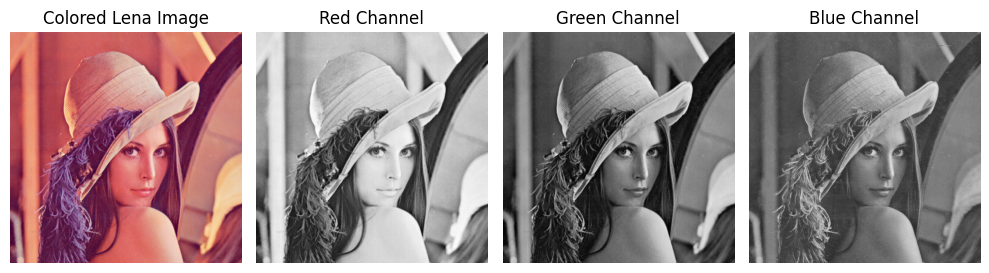

In [ ]:
# Load Lena image from URL safely
url = "http://www.image.ntua.gr/~tpar/LABimage/lena.png"
try:
    HTTP_response = urllib.request.urlopen(url)
    arr = np.asarray(bytearray(HTTP_response.read()), dtype=np.uint8)
    lena_BGR = cv2.imdecode(arr, cv2.IMREAD_COLOR)
except Exception as e:
    print(f"Error loading image: {e}")
    lena_BGR = None

# Proceed only if image is loaded successfully
if lena_BGR is not None:
    # Convert BGR to RGB
    lena = cv2.cvtColor(lena_BGR, cv2.COLOR_BGR2RGB)

    # Print shape and min/max values
    print("Shape:", lena.shape)
    print("Values min/max:", lena.min(), lena.max())

    # Extract individual color channels
    lena_R, lena_G, lena_B = lena[:, :, 0], lena[:, :, 1], lena[:, :, 2]

    # Display the original image and separate channels
    plt.figure(figsize=(10, 5))

    # Original image
    plt.subplot(1, 4, 1)
    plt.imshow(lena)
    plt.title("Colored Lena Image")
    plt.axis("off")

    # Red channel
    plt.subplot(1, 4, 2)
    plt.imshow(lena_R, cmap="gray")
    plt.title("Red Channel")
    plt.axis("off")

    # Green channel
    plt.subplot(1, 4, 3)
    plt.imshow(lena_G, cmap="gray")
    plt.title("Green Channel")
    plt.axis("off")

    # Blue channel
    plt.subplot(1, 4, 4)
    plt.imshow(lena_B, cmap="gray")
    plt.title("Blue Channel")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Image could not be loaded. Check your internet connection or URL.")

Shape: (512, 512)
Values min/max: 0 255


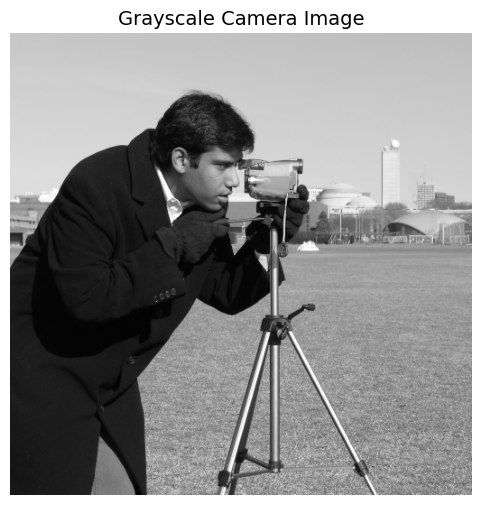

In [ ]:
# Load camera image safely
try:
    camera = data.camera()
except AttributeError:
    print("Error: 'data.camera()' is not available in this skimage version.")
    camera = None

# Proceed only if image is loaded successfully
if camera is not None:
    # Print shape and min/max values
    print("Shape:", camera.shape)
    print("Values min/max:", camera.min(), camera.max())

    # Display the grayscale camera image
    plt.figure(figsize=(6, 6))
    plt.imshow(camera, cmap="gray")
    plt.title("Grayscale Camera Image", fontsize=14)
    plt.axis("off")
    plt.show()
else:
    print("Camera image could not be loaded.")

#### Helper Functions

Η συνάρτηση **visualize_L_pyramid(pyramid, label="Image")** εμφανίζει όλα τα επίπεδα μιας Laplacian Πυραμίδας, είτε ασπρόμαυρης είτε έγχρωμης.



In [ ]:
# Visualizes all levels of a Laplacian pyramid (grayscale or RGB)
def visualize_L_pyramid(pyramid, label="Image"):
    # Check if pyramid is color (list of 3 separate pyramids)
    is_color = isinstance(pyramid, list) and len(pyramid) == 3 and all(isinstance(p, list) for p in pyramid)
    color_labels = ['RED', 'GREEN', 'BLUE']

    # Handle grayscale pyramid
    if not is_color:
        num_levels = len(pyramid)
        plt.figure(figsize=(2.5 * num_levels, 2.5))
        plt.suptitle(f'Laplacian Pyramid - {label}', fontsize=16)

        for i in range(num_levels):
            level = pyramid[i]
            plt.subplot(1, num_levels, i + 1)
            plt.imshow(level, cmap="gray")
            plt.title(f"L[{i}]")
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    # Handle color pyramid
    else:
        num_levels = len(pyramid[0])
        for c in range(3):
            plt.figure(figsize=(2.5 * num_levels, 2.5))
            plt.suptitle(f'Laplacian Pyramid - {label} ({color_labels[c]})', fontsize=16)

            for i in range(num_levels):
                level = pyramid[c][i]
                plt.subplot(1, num_levels, i + 1)
                plt.imshow(level, cmap="gray")
                plt.title(f"L[{i}]")
                plt.axis("off")

            plt.tight_layout()
            plt.show()

Η συνάρτηση **compare_to_original(image, reconstructed_img)** συγκρίνει την αρχική εικόνα με μια ανακατασκευασμένη εκδοχή της, παρέχοντας τόσο οπτική όσο και αριθμητική αξιολόγηση της διαφοράς.

Υπολογίζει και εμφανίζει βασικές μετρικές διαφοράς:
   - Μέγιστη απόλυτη διαφορά (max)
   - Μέση απόλυτη διαφορά (mean)
   - Μέσο τετραγωνικό σφάλμα (MSE)



In [ ]:
# Compares the original and reconstructed image visually and numerically
def compare_to_original(image, reconstructed_img):
    rcParams['figure.figsize'] = (8, 4)

    # Clip values and convert to uint8 for valid visualization and comparison
    image_disp = np.clip(image, 0, 255).astype(np.uint8)
    reconstructed_disp = np.clip(reconstructed_img, 0, 255).astype(np.uint8)

    # Display original and reconstructed images side by side
    fig, axes = plt.subplots(1, 2)
    axes[0].imshow(image_disp, cmap="gray" if image_disp.ndim == 2 else None)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(reconstructed_disp, cmap="gray" if reconstructed_disp.ndim == 2 else None)
    axes[1].set_title("Reconstructed Image")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # Use tolerance-based comparison to account for small floating point errors
    if np.allclose(reconstructed_disp, image_disp, atol=1):
        print("Original Image successfully reconstructed (visually identical)!")
    else:
        print("Image Distorted! Possible data loss in reconstruction.")

    # Compute and print numeric difference statistics
    diff = image_disp.astype(np.float32) - reconstructed_disp.astype(np.float32)
    abs_diff = np.abs(diff)
    mse = np.mean(diff ** 2)

    print("Max pixel difference:", np.max(abs_diff))
    print("Mean pixel difference:", np.mean(abs_diff))
    print("Mean squared error (MSE):", mse)

#### Implementation

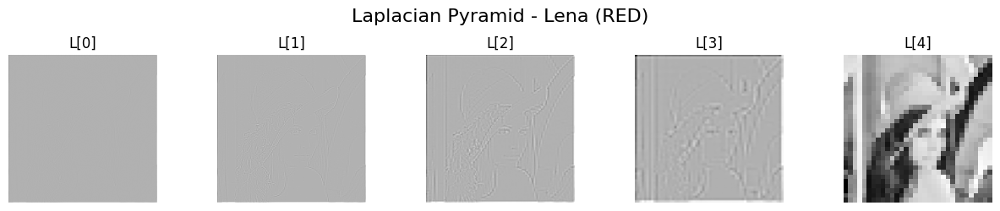

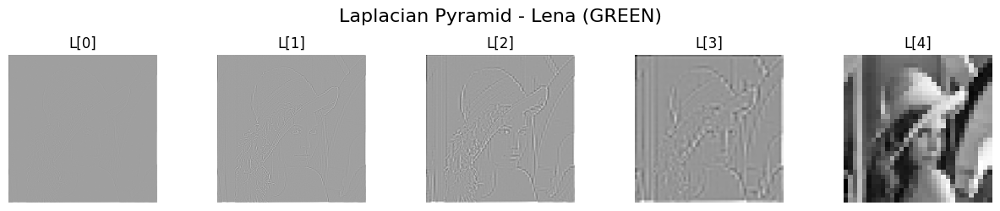

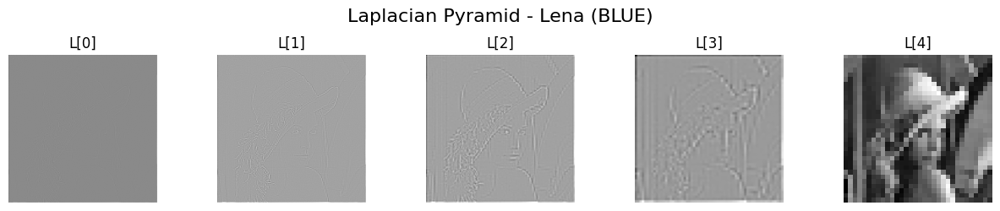

In [ ]:
# Implementation on lena image
lap_pyr_lena = [L_Pyramid(lena[:, :, c], a=0.6, depth=5) for c in range(3)]
reconstructed_lena_channels = [L_Pyramid_Decode(lap_pyr_lena[c], a=0.6) for c in range(3)]
reconstructed_lena = np.stack(reconstructed_lena_channels, axis=2)
visualize_L_pyramid(lap_pyr_lena, label="Lena")

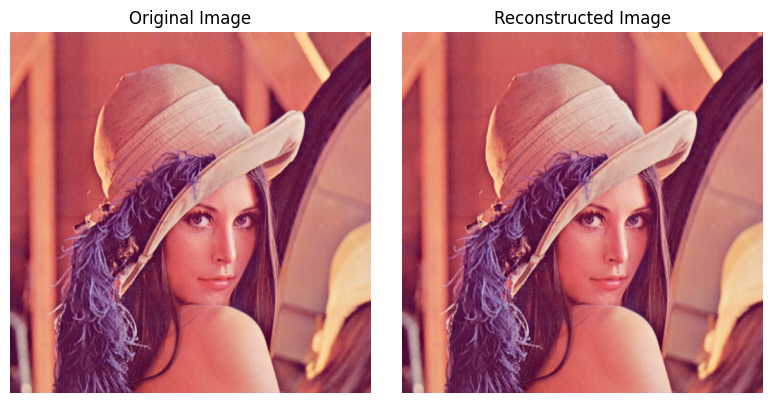

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0045776367
Mean squared error (MSE): 0.0045776367


In [ ]:
# Visualize results
compare_to_original(reconstructed_lena, lena)

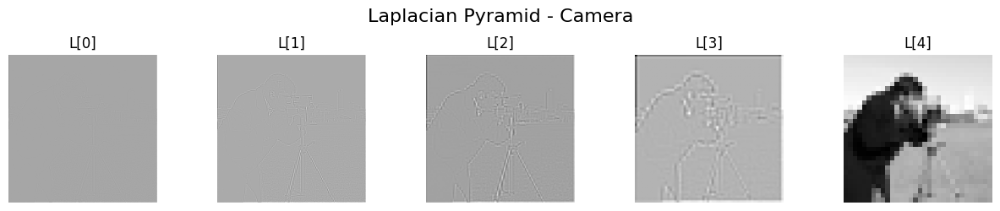

In [ ]:
# Implementation on camera image
lap_pyr_camera = L_Pyramid(camera, a=0.6, depth=5)
reconstructed_camera = L_Pyramid_Decode(lap_pyr_camera, a=0.6)
visualize_L_pyramid(lap_pyr_camera, label="Camera")

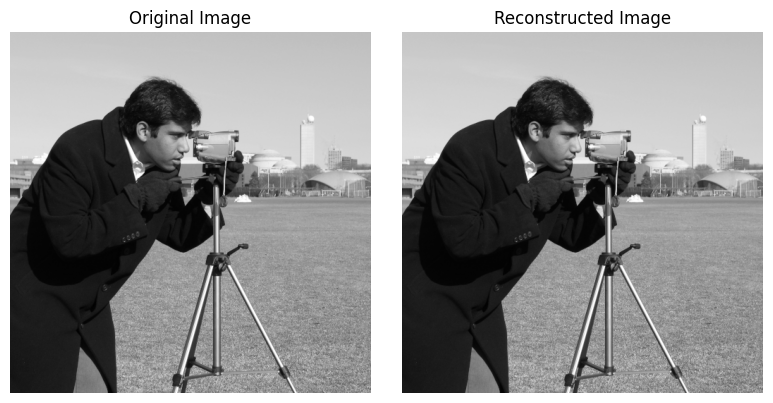

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.009983063
Mean squared error (MSE): 0.009983063


In [ ]:
# Visualize results
compare_to_original(reconstructed_camera, camera)

#### Conclusions

Οι Laplacian Πυραμίδες που κατασκευάστηκαν για τις εικόνες Lena και Camera (με a = 0.6 και depth = 5) κατάφεραν να αναπαραστήσουν την εικόνα με εξαιρετική ακρίβεια.

- Η ανακατασκευή είναι οπτικά ταυτόσημη με την αρχική εικόνα.
- Η μέγιστη απόλυτη διαφορά σε pixel είναι 1, ενώ η μέση απόλυτη διαφορά και το MSE είναι εξαιρετικά μικρά.
- Τα επίπεδα της πυραμίδας περιλαμβάνουν τις λεπτομέρειες της εικόνας σε διαφορετικές κλίμακες, και το τελευταίο επίπεδο (L[4]) περιέχει τη συμπιεσμένη πληροφορία.

Τα αποτελέσματα αυτά επιβεβαιώνουν την αποτελεσματικότητα της Laplacian Πυραμίδας για ανάλυση πολλαπλής κλίμακας και συμπίεση εικόνας, όπως περιγράφεται στο άρθρο των Burt & Adelson (1983).


### **2. Reconstruction analysis with varying 'a' values (0.3 to 0.7)**

#### Helper Functions

Η συνάρτηση **build_and_decode_pyramids_for_a(image, a_values, depth)** κατασκευάζει και αποκωδικοποιεί Laplacian Πυραμίδες για διαφορετικές τιμές του παραμέτρου `a`, σε βάθος `depth`.

In [ ]:
# Builds and decodes Laplacian pyramids for different 'a' values
def build_and_decode_pyramids_for_a(image, a_values, depth):
    pyramids = {}
    reconstructions = {}

    for a in a_values:
        if image.ndim == 2:
            lap_pyr = L_Pyramid(image, a=a, depth=depth)
            reconstructed = L_Pyramid_Decode(lap_pyr, a=a)
        else:
            lap_pyr = [L_Pyramid(image[:, :, c], a=a, depth=depth) for c in range(3)]
            reconstructed_channels = [L_Pyramid_Decode(lap_pyr[c], a=a) for c in range(3)]
            reconstructed = np.stack(reconstructed_channels, axis=2)

        pyramids[a] = lap_pyr
        reconstructions[a] = reconstructed

    return pyramids, reconstructions

Η συνάρτηση **visualize_pyramids_by_a(pyramids, label="Image")** εμφανίζει όλα τα επίπεδα των Laplacian Πυραμίδων που έχουν κατασκευαστεί για διαφορετικές τιμές του παραμέτρου `a`.

In [ ]:
# Visualizes Laplacian pyramids for different values of 'a'
def visualize_pyramids_by_a(pyramids, label="Image"):
    for a, pyramid in pyramids.items():
        visualize_L_pyramid(pyramid, label=f"{label} (a={a})")

Η συνάρτηση **compute_a_errors(original_image, reconstructions)** υπολογίζει μετρικές σφάλματος (μέση απόλυτη διαφορά, μέγιστη διαφορά, MSE) για κάθε τιμή της παραμέτρου a, συγκρίνοντας την ανακατασκευασμένη εικόνα με την αρχική.

In [ ]:
# Computes reconstruction errors for different 'a' values
def compute_a_errors(original_image, reconstructions):
    original_image = np.clip(original_image, 0, 255).astype(np.uint8)
    summary = []

    for a, reconstructed in reconstructions.items():
        print(f"\nComparing a = {a}")
        reconstructed_uint8 = np.clip(reconstructed, 0, 255).astype(np.uint8)
        compare_to_original(original_image, reconstructed_uint8)

        diff = original_image.astype(np.float32) - reconstructed_uint8.astype(np.float32)
        mean_diff = np.mean(np.abs(diff))
        max_diff = np.max(np.abs(diff))
        mse = np.mean(diff ** 2)

        summary.append((a, mean_diff, max_diff, mse))

    return summary

Η συνάρτηση **print_a_error_summary(summary, label)** εμφανίζει σε μορφή πίνακα τα σφάλματα ανακατασκευής για κάθε τιμή του παραμέτρου a.

In [ ]:
# Prints a formatted summary table for reconstruction errors per 'a'
def print_a_error_summary(summary, label="Image"):
    print(f"\nSummary of Reconstruction Errors ({label}):")
    print(f"{'a':>5} | {'Mean Abs Diff':>15} | {'Max Abs Diff':>13} | {'MSE':>10}")
    print("-" * 55)
    for a, mean_diff, max_diff, mse in summary:
        print(f"{a:>5.2f} | {mean_diff:>15.5f} | {max_diff:>13} | {mse:>10.5f}")

#### Implementation

In [ ]:
# Values of 'a' from 0.3 to 0.7
a_values = [0.3, 0.4, 0.5, 0.6, 0.7]
depth = 5

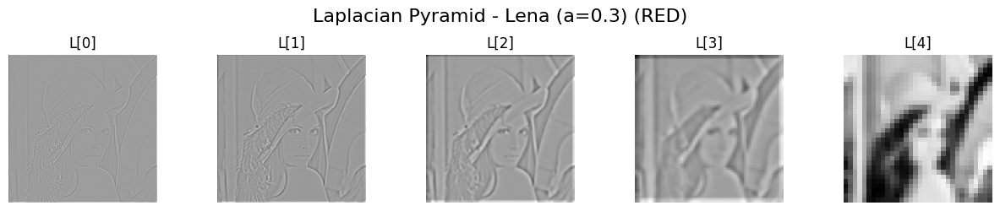

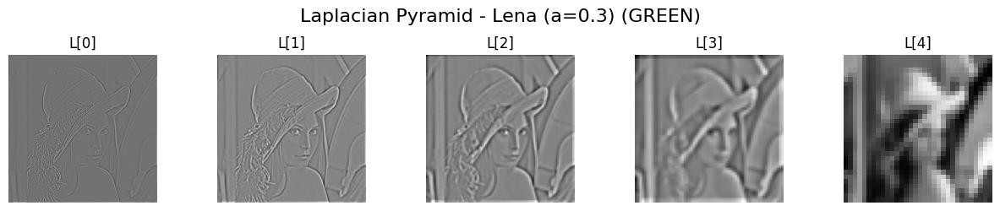

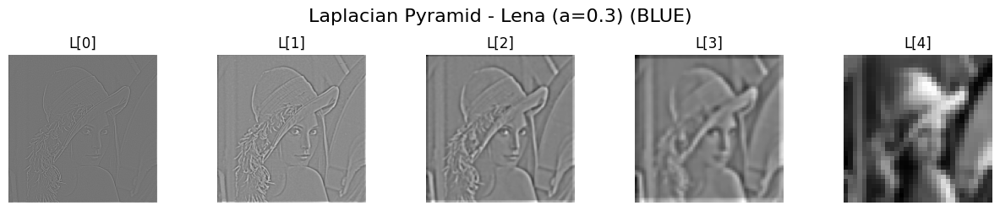

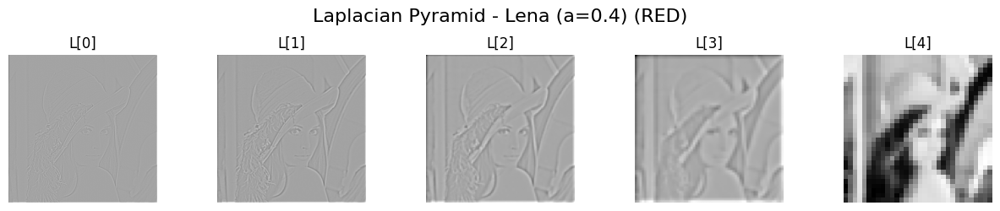

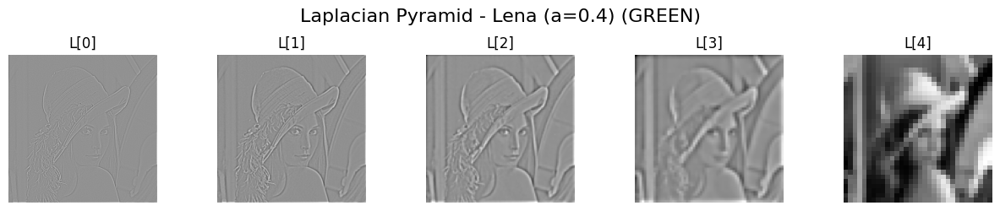

...

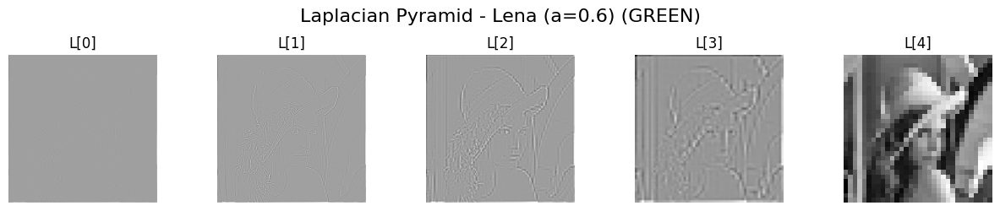

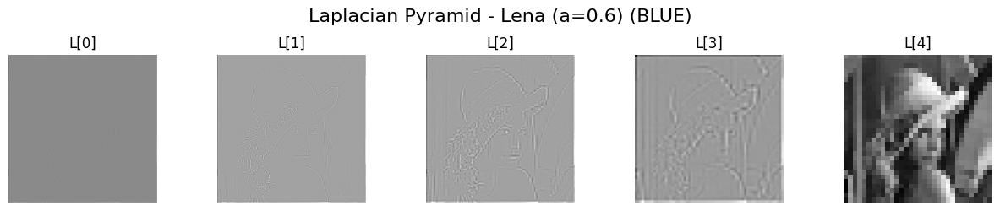

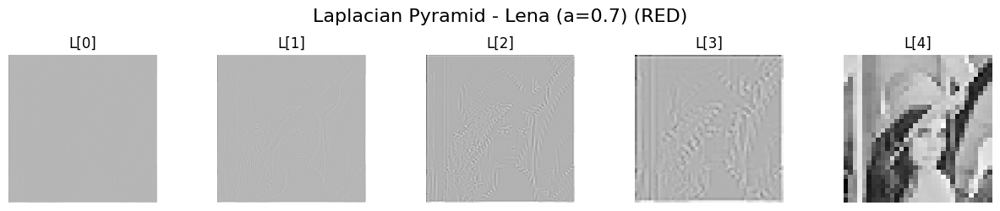

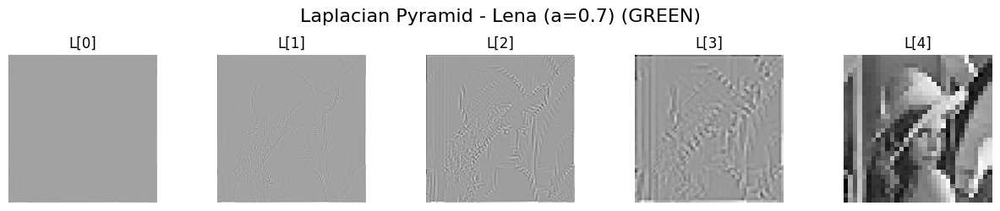

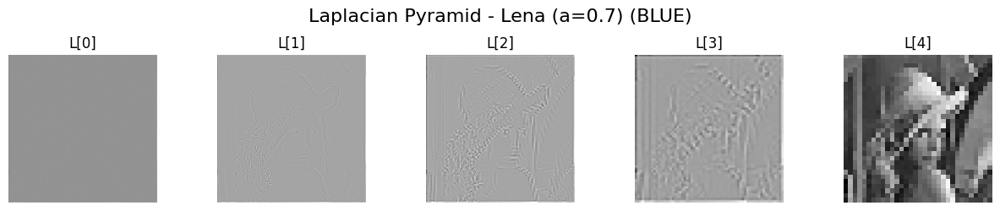

In [ ]:
# Implementation on lena image
lena_pyr_a, lena_recon_a = build_and_decode_pyramids_for_a(lena, a_values, depth)
visualize_pyramids_by_a(lena_pyr_a, label="Lena")


Comparing a = 0.3


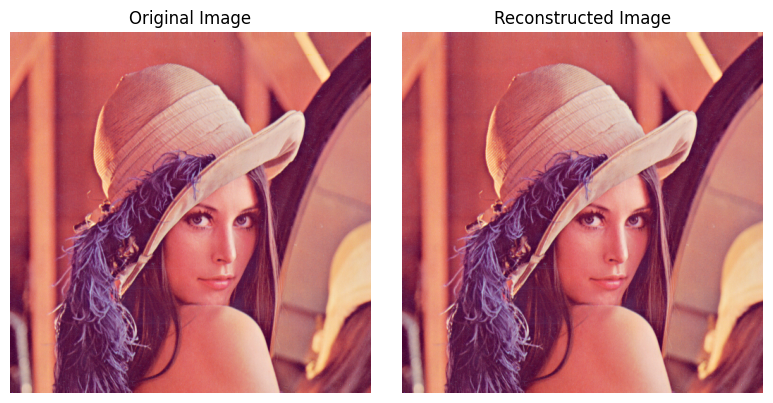

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.001092275
Mean squared error (MSE): 0.001092275

Comparing a = 0.4


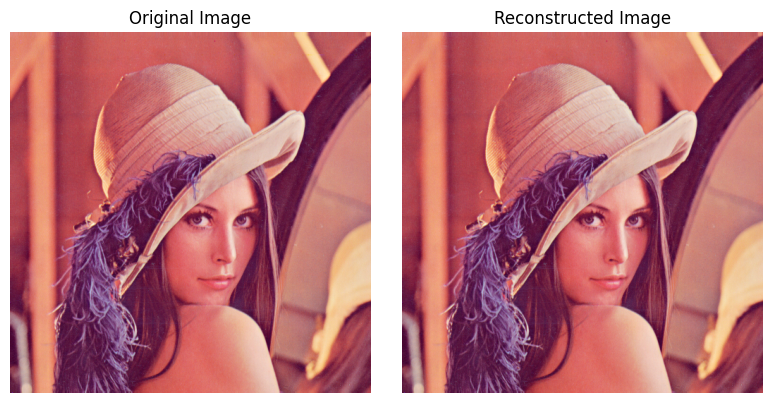

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0008468628
Mean squared error (MSE): 0.0008468628

Comparing a = 0.5


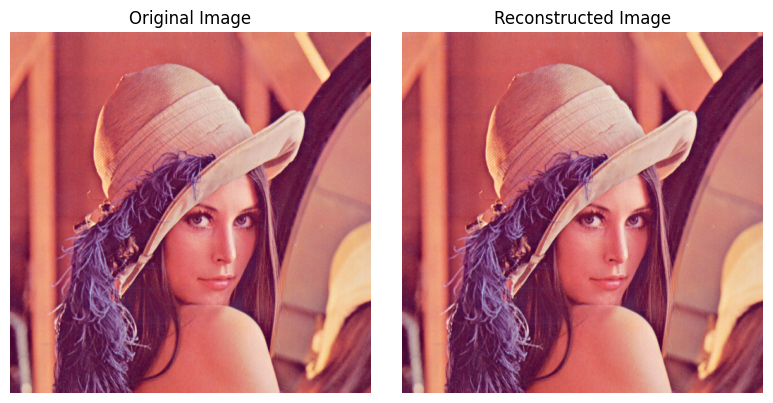

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 0.0
Mean pixel difference: 0.0
Mean squared error (MSE): 0.0

Comparing a = 0.6


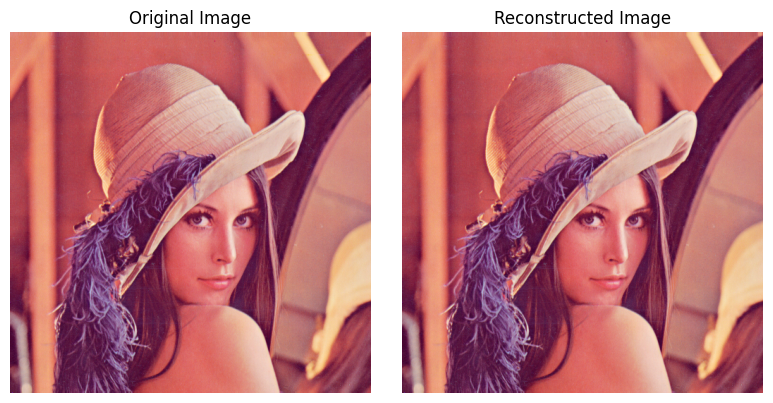

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0045776367
Mean squared error (MSE): 0.0045776367

Comparing a = 0.7


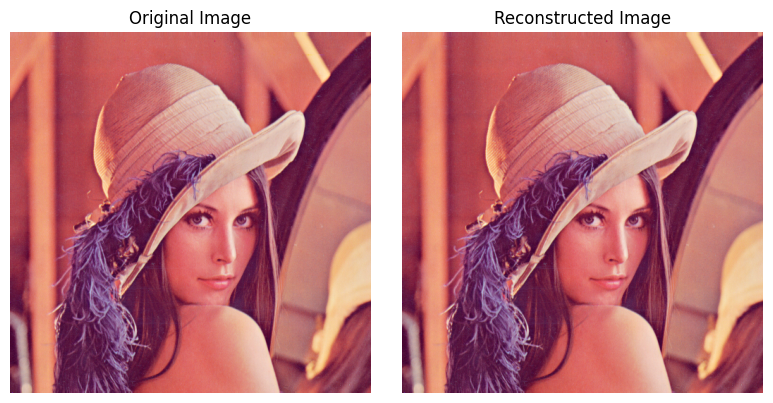

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.015595754
Mean squared error (MSE): 0.015595754


In [ ]:
# Compute errors for different a values
summary = compute_a_errors(lena, lena_recon_a)

In [ ]:
# Print summary
print_a_error_summary(summary, label="Lena")


Summary of Reconstruction Errors (Lena):
    a |   Mean Abs Diff |  Max Abs Diff |        MSE
-------------------------------------------------------
 0.30 |         0.00109 |           1.0 |    0.00109
 0.40 |         0.00085 |           1.0 |    0.00085
 0.50 |         0.00000 |           0.0 |    0.00000
 0.60 |         0.00458 |           1.0 |    0.00458
 0.70 |         0.01560 |           1.0 |    0.01560


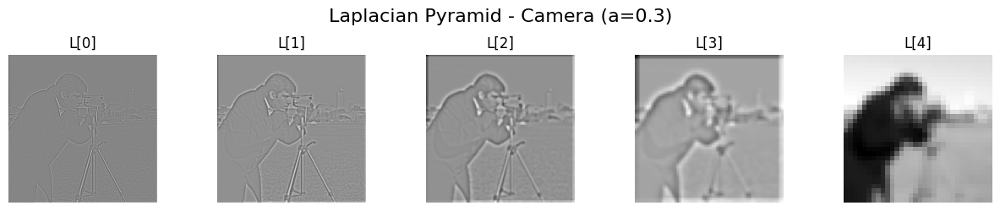

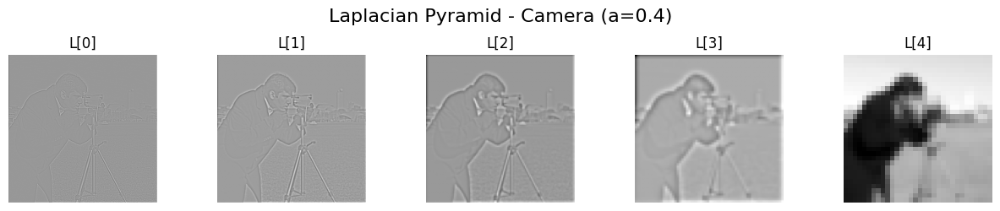

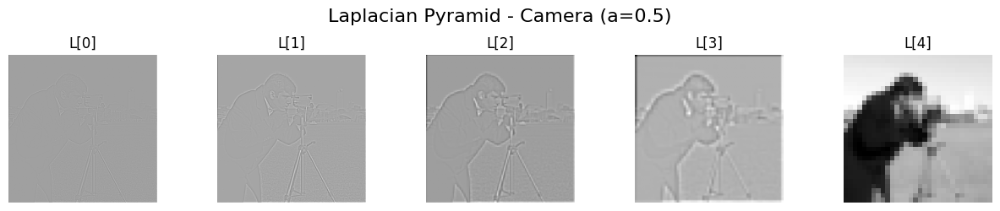

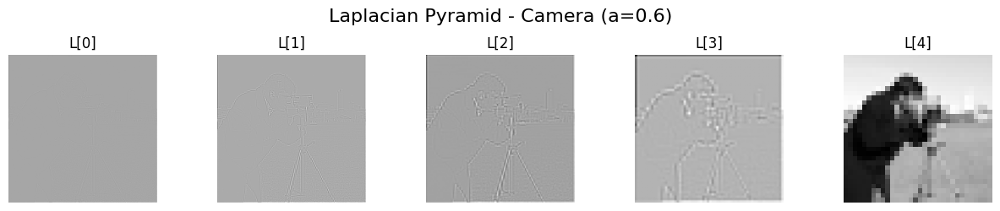

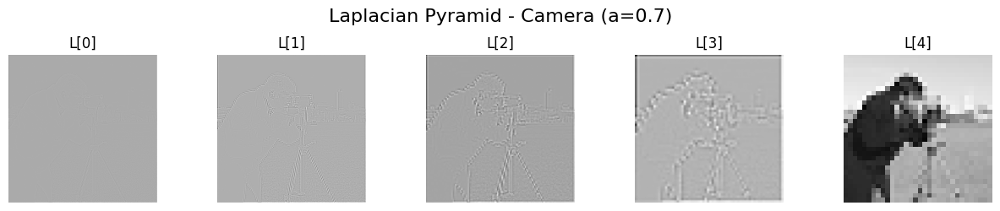

In [ ]:
# Implementation on camera image
camera_pyr_a, camera_recon_a = build_and_decode_pyramids_for_a(camera, a_values, depth)
visualize_pyramids_by_a(camera_pyr_a, label="Camera")


Comparing a = 0.3


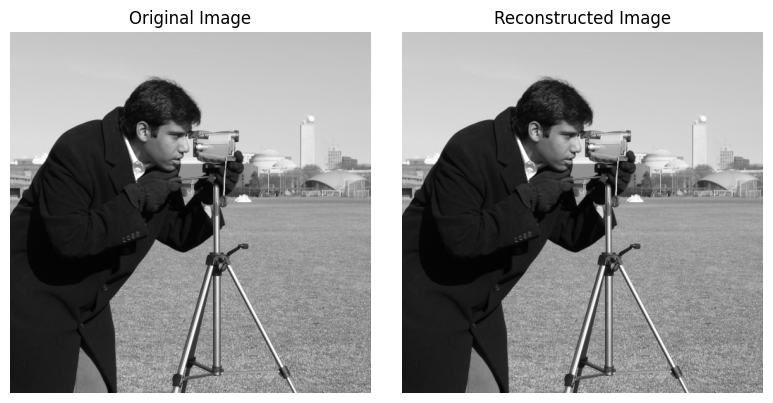

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0047302246
Mean squared error (MSE): 0.0047302246

Comparing a = 0.4


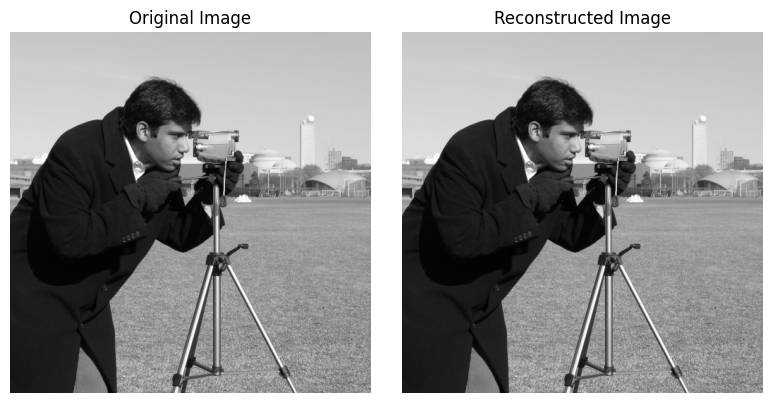

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0049858093
Mean squared error (MSE): 0.0049858093

Comparing a = 0.5


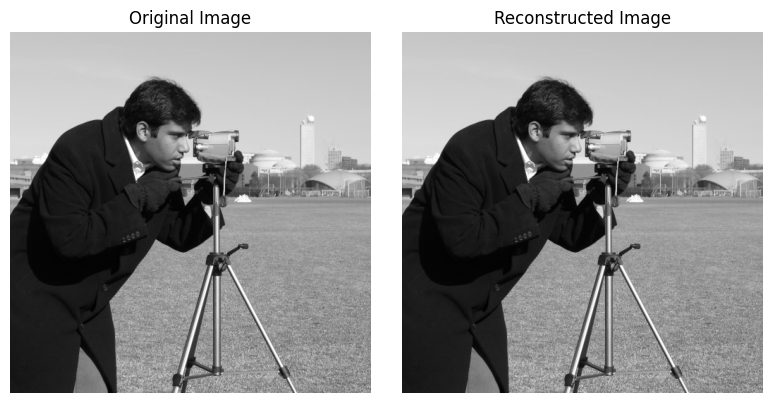

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 0.0
Mean pixel difference: 0.0
Mean squared error (MSE): 0.0

Comparing a = 0.6


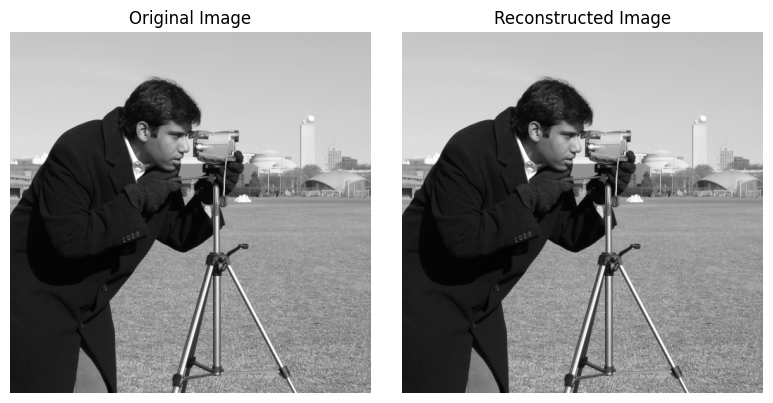

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.009983063
Mean squared error (MSE): 0.009983063

Comparing a = 0.7


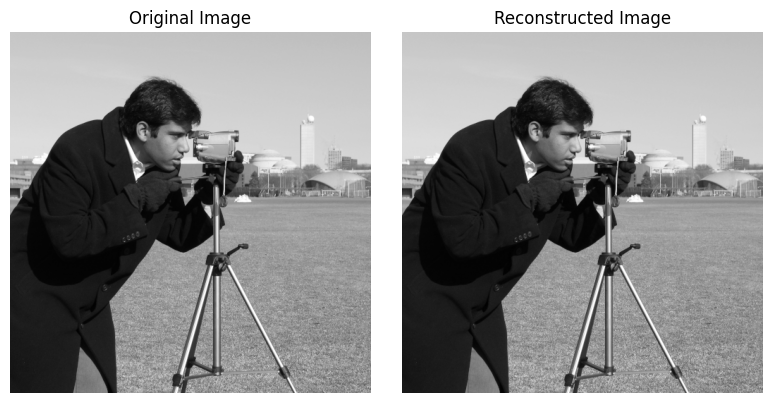

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.030311584
Mean squared error (MSE): 0.030311584


In [ ]:
# Compute errors for different a values
summary = compute_a_errors(camera, camera_recon_a)

In [ ]:
# Print summary
print_a_error_summary(summary, label="Camera")


Summary of Reconstruction Errors (Camera):
    a |   Mean Abs Diff |  Max Abs Diff |        MSE
-------------------------------------------------------
 0.30 |         0.00473 |           1.0 |    0.00473
 0.40 |         0.00499 |           1.0 |    0.00499
 0.50 |         0.00000 |           0.0 |    0.00000
 0.60 |         0.00998 |           1.0 |    0.00998
 0.70 |         0.03031 |           1.0 |    0.03031


#### Conclusions

Οι ανακατασκευές εικόνων για διαφορετικές τιμές του παραμέτρου **a** (0.3 έως 0.7) παρουσιάζουν **ελάχιστες διαφοροποιήσεις** ως προς την ποιότητα, και στις δύο εικόνες **Lena** και **Camera**.

- Οι εικόνες ανακατασκευάζονται με **οπτικά ταυτόσημο** αποτέλεσμα για όλες τις τιμές του `a`
- Το **MSE** και η **μέση απόλυτη διαφορά** αυξάνονται ελαφρώς για τιμές `a` κοντά στα άκρα (0.3 ή 0.7)
- Η **βελτιστοποιημένη τιμή `a` ως προς σφάλμα ανακατασκευής** φαίνεται να είναι γύρω στο **0.5–0.6** για κάθε εικόνα

Αυτό επιβεβαιώνει ότι η παράμετρος `a`, αν και επηρεάζει τη μορφή του Gaussian-like πυρήνα, έχει **περιορισμένη επίδραση στην τελική πιστότητα** της εικόνας όταν εφαρμόζεται με σωστό βάθος.


### **3. Effect of depth variation (3 to 6) on reconstruction quality**

#### Helper Functions

Η συνάρτηση **build_and_decode_pyramids(image, depths, a)** κατασκευάζει και αποκωδικοποιεί Laplacian Πυραμίδες για διαφορετικές τιμές βάθους (`depth`), χρησιμοποιώντας τη σταθερή παράμετρο `a`.


In [ ]:
# Builds Laplacian pyramids and reconstructs the image for each depth
def build_and_decode_pyramids(image, depths, a=0.6):
    pyramids = {}
    reconstructions = {}

    for depth in depths:
        if image.ndim == 2:
            lap_pyr = L_Pyramid(image, a=a, depth=depth)
            reconstructed = L_Pyramid_Decode(lap_pyr, a=a)
        else:
            lap_pyr = [L_Pyramid(image[:, :, c], a=a, depth=depth) for c in range(3)]
            reconstructed_channels = [L_Pyramid_Decode(lap_pyr[c], a=a) for c in range(3)]
            reconstructed = np.stack(reconstructed_channels, axis=2)

        pyramids[depth] = lap_pyr
        reconstructions[depth] = reconstructed

    return pyramids, reconstructions

Η συνάρτηση **visualize_pyramids_by_depth(pyramids, label="Image")** εμφανίζει οπτικά τις Laplacian Πυραμίδες για διαφορετικά βάθη (`depth`) που έχουν εφαρμοστεί στην ίδια εικόνα.



In [ ]:
# Visualizes Laplacian pyramids by depth
def visualize_pyramids_by_depth(pyramids, label="Image"):
    for depth, pyramid in pyramids.items():
        visualize_L_pyramid(pyramid, label=f"{label} (depth={depth})")

Η συνάρτηση **compute_depth_errors(original_image, reconstructions)** υπολογίζει τα σφάλματα ανακατασκευής της αρχικής εικόνας για κάθε τιμή βάθους (depth), επιστρέφοντας μετρικές όπως μέση απόλυτη διαφορά, μέγιστη διαφορά και MSE.

In [ ]:
# Computes reconstruction errors for different depths
def compute_depth_errors(original_image, reconstructions):
    original_image = np.clip(original_image, 0, 255).astype(np.uint8)
    summary = []

    for depth, reconstructed in reconstructions.items():
        print(f"\nComparing depth = {depth}")
        reconstructed_uint8 = np.clip(reconstructed, 0, 255).astype(np.uint8)

        compare_to_original(original_image, reconstructed_uint8)

        diff = original_image.astype(np.float32) - reconstructed_uint8.astype(np.float32)
        mean_diff = np.mean(np.abs(diff))
        max_diff = np.max(np.abs(diff))
        mse = np.mean(diff ** 2)

        summary.append((depth, mean_diff, max_diff, mse))

    return summary

Η συνάρτηση **print_depth_error_summary(summary, label)** εμφανίζει σε μορφή πίνακα τα συνοπτικά σφάλματα ανακατασκευής για κάθε βάθος πυραμίδας, μετρώντας τη μέση και μέγιστη απόκλιση, καθώς και το MSE.

In [ ]:
# Prints a formatted summary table for reconstruction errors
def print_depth_error_summary(summary, label="Image"):
    print(f"\nSummary of Reconstruction Errors ({label}):")
    print(f"{'Depth':>5} | {'Mean Abs Diff':>15} | {'Max Abs Diff':>13} | {'MSE':>10}")
    print("-" * 55)
    for depth, mean_diff, max_diff, mse in summary:
        print(f"{depth:>5} | {mean_diff:>15.5f} | {max_diff:>13} | {mse:>10.5f}")

#### Implementation

In [ ]:
# Define parameters
a = 0.6
depth_values = [3, 4, 5, 6]

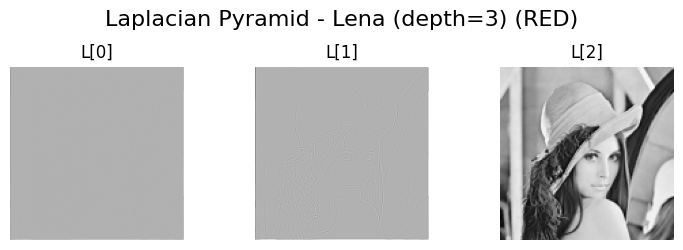

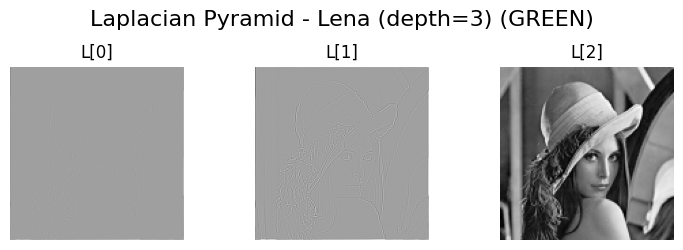

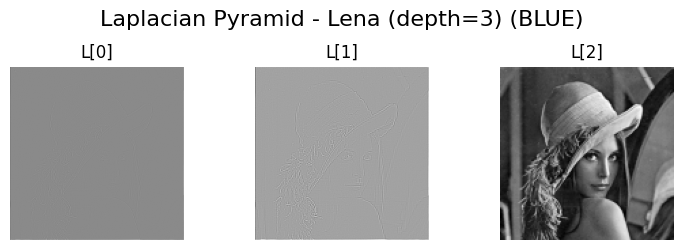

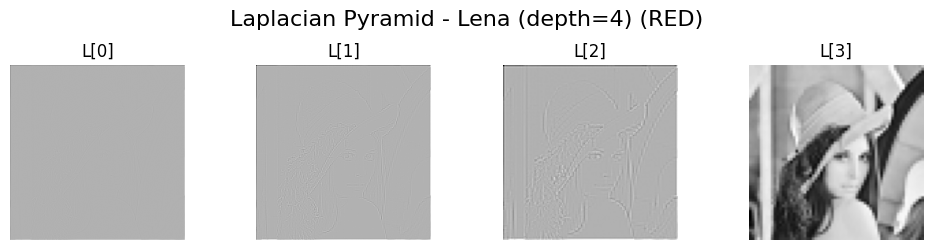

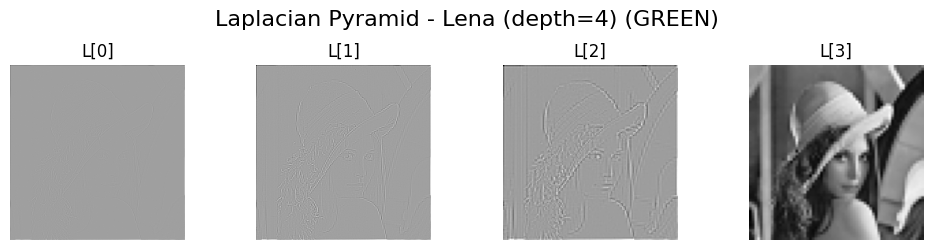

...

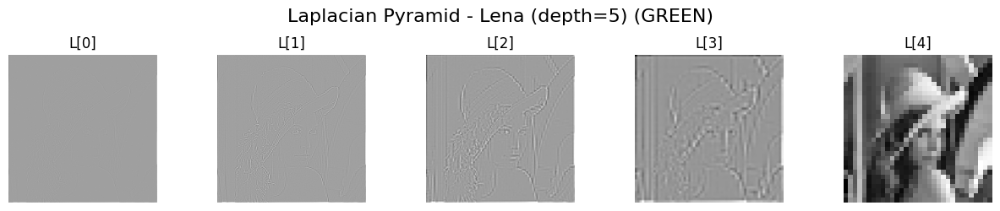

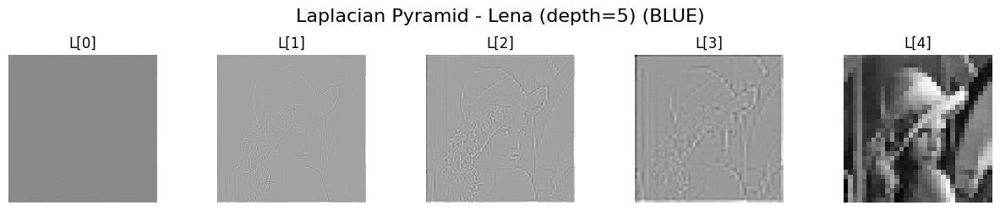

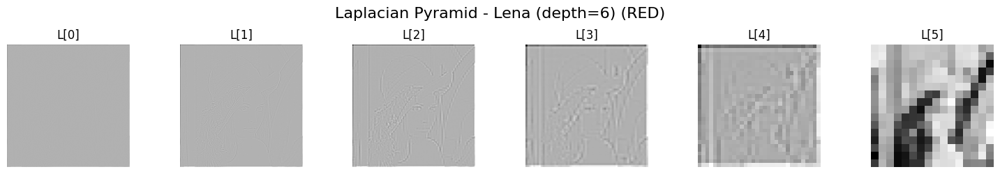

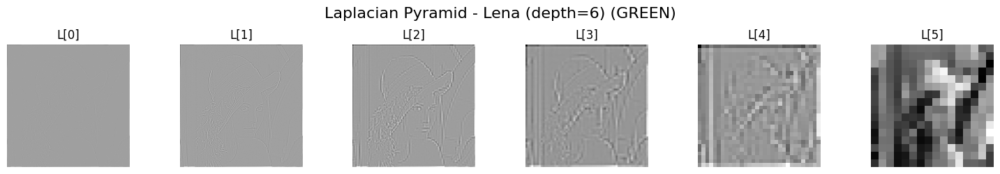

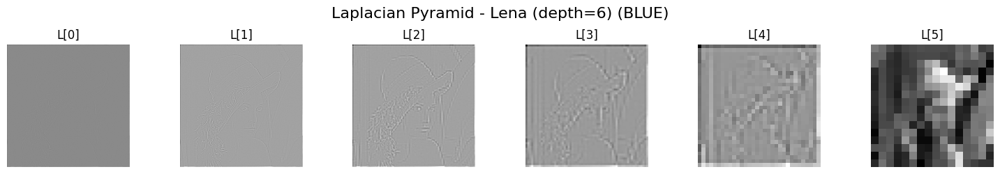

In [ ]:
# Implementation on lena image
lena_pyr, lena_recon = build_and_decode_pyramids(lena, depth_values, a=0.6)
visualize_pyramids_by_depth(lena_pyr, label="Lena")


Comparing depth = 3


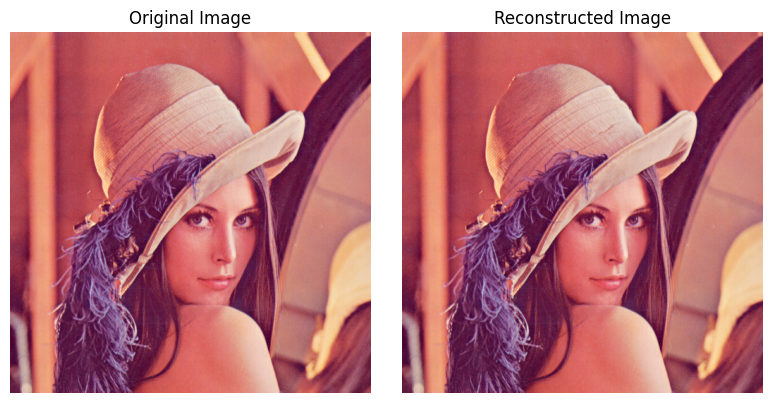

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0009613037
Mean squared error (MSE): 0.0009613037

Comparing depth = 4


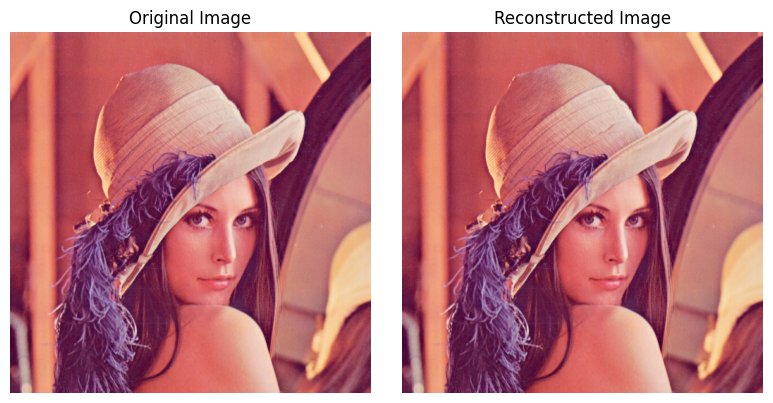

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0025431316
Mean squared error (MSE): 0.0025431316

Comparing depth = 5


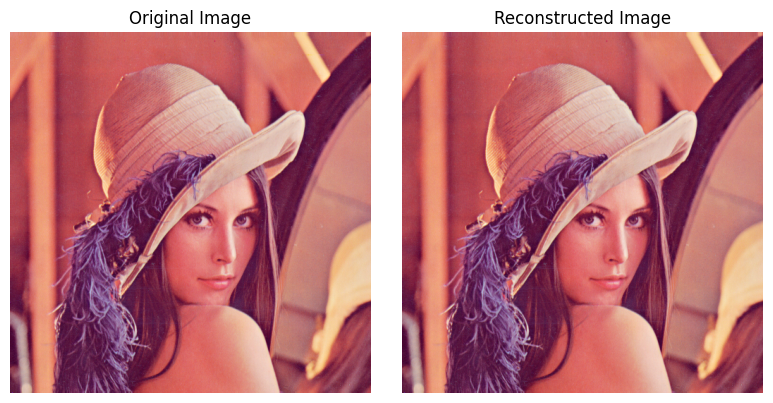

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0045776367
Mean squared error (MSE): 0.0045776367

Comparing depth = 6


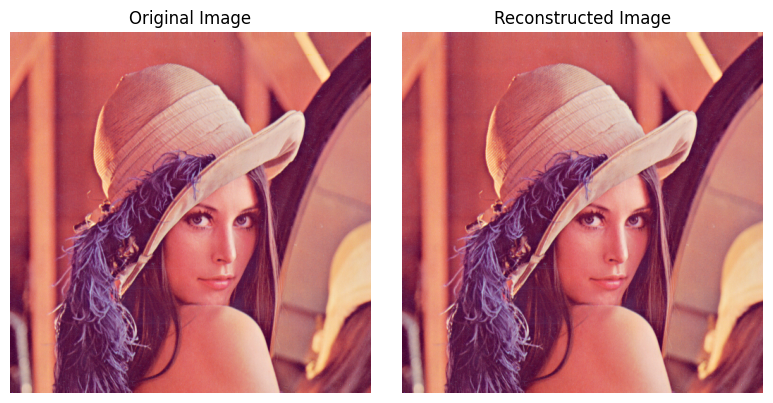

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.008349101
Mean squared error (MSE): 0.008349101


In [ ]:
# Compute errors for different depth values
summary = compute_depth_errors(lena, lena_recon)

In [ ]:
# Print summary
print_depth_error_summary(summary, label="Lena")


Summary of Reconstruction Errors (Lena):
Depth |   Mean Abs Diff |  Max Abs Diff |        MSE
-------------------------------------------------------
    3 |         0.00096 |           1.0 |    0.00096
    4 |         0.00254 |           1.0 |    0.00254
    5 |         0.00458 |           1.0 |    0.00458
    6 |         0.00835 |           1.0 |    0.00835


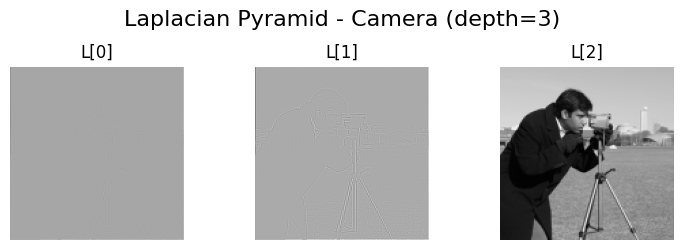

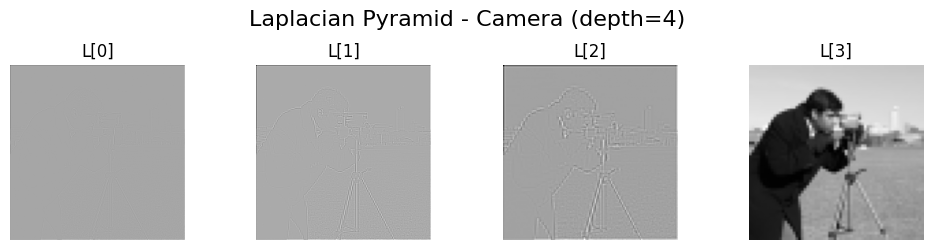

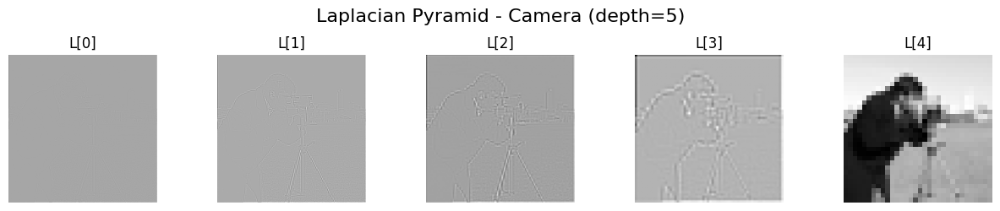

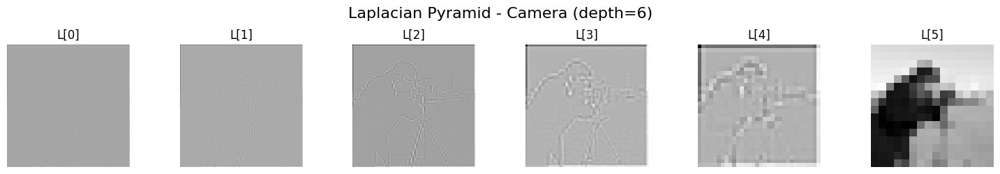

In [ ]:
# Implementation on camera image
camera_pyr, camera_recon = build_and_decode_pyramids(camera, depth_values, a=0.6)
visualize_pyramids_by_depth(camera_pyr, label="Camera")


Comparing depth = 3


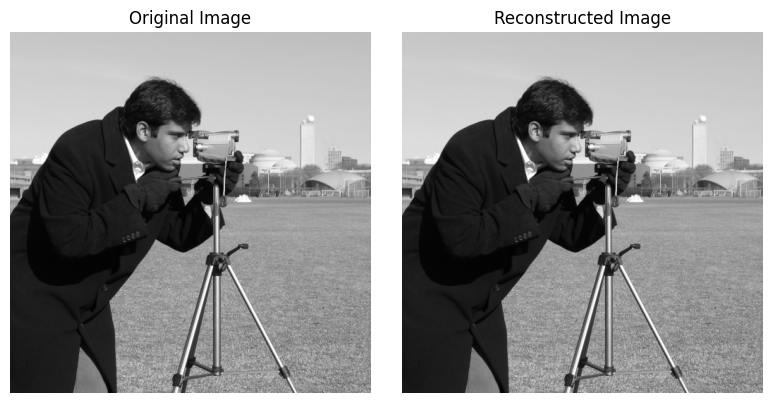

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.0014419556
Mean squared error (MSE): 0.0014419556

Comparing depth = 4


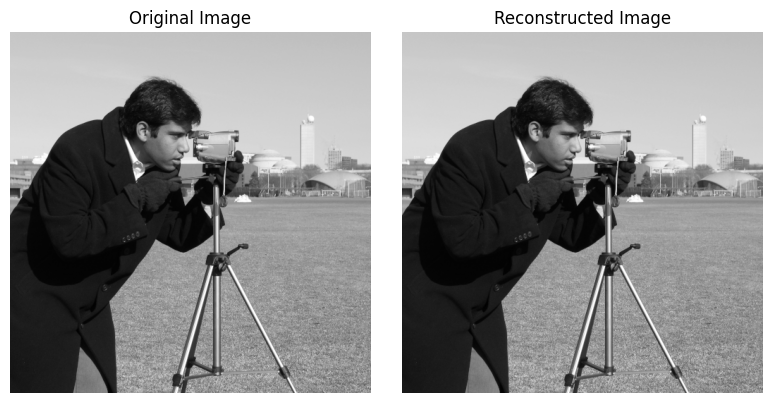

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.004699707
Mean squared error (MSE): 0.004699707

Comparing depth = 5


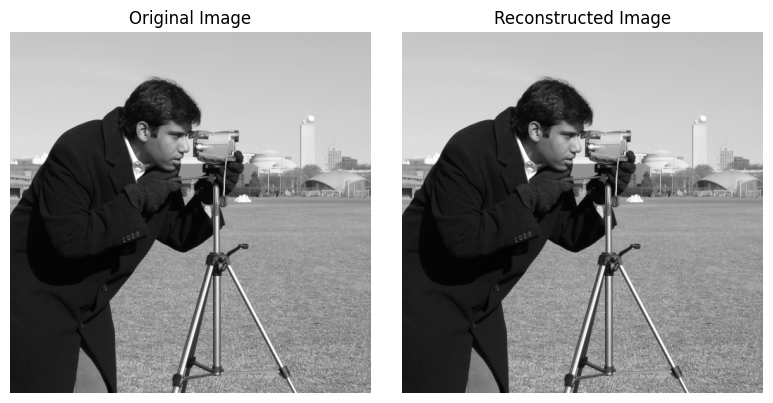

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.009983063
Mean squared error (MSE): 0.009983063

Comparing depth = 6


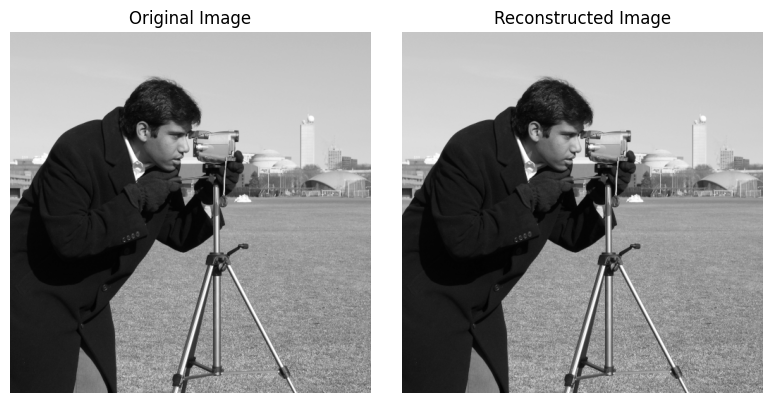

Original Image successfully reconstructed (visually identical)!
Max pixel difference: 1.0
Mean pixel difference: 0.014568329
Mean squared error (MSE): 0.014568329


In [ ]:
# Compute errors for different depth values
summary = compute_depth_errors(camera, camera_recon)

In [ ]:
# Print summary
print_depth_error_summary(summary, label="Camera")


Summary of Reconstruction Errors (Camera):
Depth |   Mean Abs Diff |  Max Abs Diff |        MSE
-------------------------------------------------------
    3 |         0.00144 |           1.0 |    0.00144
    4 |         0.00470 |           1.0 |    0.00470
    5 |         0.00998 |           1.0 |    0.00998
    6 |         0.01457 |           1.0 |    0.01457


#### Conclusions

Η μεταβολή του βάθους (`depth = 3–6`) στην κατασκευή της Laplacian Πυραμίδας επηρεάζει την ακρίβεια της ανακατασκευής ως εξής:

Lena:
- Το MSE παραμένει χαμηλό σε όλες τις περιπτώσεις (0.00096 έως 0.00835)
- Οπτικά, η ανακατασκευή είναι ταυτόσημη με την αρχική εικόνα
- Η βέλτιστη ισορροπία μεταξύ πιστότητας και υπολογιστικού κόστους φαίνεται στο depth = 4 ή 5

Camera:
- Παρόμοια συμπεριφορά με την Lena, με αύξηση του σφάλματος όσο αυξάνεται το βάθος
- Το MSE κυμαίνεται από 0.00144 έως 0.01457
- Όλα τα αποτελέσματα είναι οπτικά άρτια, αλλά η αριθμητική απόκλιση αυξάνεται σταδιακά


Συνεπώς, η ανακατασκευή παραμένει ποιοτικά ακριβής, με μικρό αριθμητικό σφάλμα, ακόμα και για μεγάλο βάθος. Για λόγους αποδοτικότητας, το depth = 4 ή 5 είναι επαρκές και σταθερό σημείο λειτουργίας.


### **4. Entropy computation and visualization for different 'a' and depth values**

#### Helper Functions

Η συνάρτηση **compute_entropy(image)** υπολογίζει την εντροπία πληροφορίας μιας εικόνας βάσει της κατανομής των τιμών φωτεινότητας (ιστογράμματος).

In [ ]:
# Computes entropy of an image (2D NumPy array)
def compute_entropy(image):
    image = np.clip(image, 0, 255).astype(np.uint8)
    hist = np.bincount(image.flatten(), minlength=256)
    prob = hist / np.sum(hist)
    prob = prob[prob > 0]
    entropy = -np.sum(prob * np.log2(prob))
    return entropy

Η συνάρτηση **compute_pyramid_entropy(pyramid)** υπολογίζει την εντροπία κάθε επιπέδου μιας Laplacian Πυραμίδας, είτε για ασπρόμαυρη είτε για έγχρωμη εικόνα (μέσος όρος RGB).

In [ ]:
# Computes entropy for each level of a Laplacian pyramid
def compute_pyramid_entropy(pyramid):
    if isinstance(pyramid, list) and isinstance(pyramid[0], list):
        # Color: average across RGB channels
        depth = len(pyramid[0])
        entropies = []
        for level in range(depth):
            level_entropy = 0
            for c in range(3):
                level_entropy += compute_entropy(pyramid[c][level])
            entropies.append(level_entropy / 3)
    else:
        # Grayscale
        entropies = [compute_entropy(level) for level in pyramid]
    return entropies

In [ ]:
# Prints entropy per level for different a and depth values
def print_entropy_summary(image, a_values, depths, fixed_depth=5, fixed_a=0.6, label="Image"):
    print(f"\nEntropy per Level for Different a values (fixed depth = {fixed_depth}) — {label}")
    for a in a_values:
        pyramid = L_Pyramid(image, a=a, depth=fixed_depth) if image.ndim == 2 else [L_Pyramid(image[:, :, c], a=a, depth=fixed_depth) for c in range(3)]
        entropies = compute_pyramid_entropy(pyramid)
        print(f"a = {a:.2f}:", " | ".join([f"L[{i}] = {e:.4f}" for i, e in enumerate(entropies)]))

    print(f"\nEntropy per Level for Different depth values (fixed a = {fixed_a}) — {label}")
    for depth in depths:
        pyramid = L_Pyramid(image, a=fixed_a, depth=depth) if image.ndim == 2 else [L_Pyramid(image[:, :, c], a=fixed_a, depth=depth) for c in range(3)]
        entropies = compute_pyramid_entropy(pyramid)
        print(f"depth = {depth}:", " | ".join([f"L[{i}] = {e:.4f}" for i, e in enumerate(entropies)]))

Η συνάρτηση **plot_entropy_analysis(image, a_values, depths, fixed_depth, fixed_a, label)** απεικονίζει την εντροπία ανά επίπεδο Laplacian Πυραμίδας:

- Στο πρώτο διάγραμμα: για πολλαπλές τιμές του a, με σταθερό depth

- Στο δεύτερο διάγραμμα: για πολλαπλά depths, με σταθερό a

Χρησιμοποιείται για την οπτική σύγκριση της πληροφορίας που περιέχεται σε κάθε επίπεδο της πυραμίδας, ανάλογα με τις παραμέτρους a και depth.

In [ ]:
# Plots entropy per level for multiple 'a' and 'depth' values side-by-side
def plot_entropy_analysis(image, a_values, depths, fixed_depth=5, fixed_a=0.6, label="Image"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot entropy vs. pyramid level for different 'a'
    for a in a_values:
        pyramid = L_Pyramid(image, a=a, depth=fixed_depth) if image.ndim == 2 else [L_Pyramid(image[:, :, c], a=a, depth=fixed_depth) for c in range(3)]
        entropies = compute_pyramid_entropy(pyramid)
        axes[0].plot(range(len(entropies)), entropies, marker='o', label=f'a = {a}')

    axes[0].set_title(f'Entropy per Level for Different a ({label})')
    axes[0].set_xlabel('Pyramid Level')
    axes[0].set_ylabel('Entropy')
    axes[0].grid(True)
    axes[0].legend()

    # Plot entropy vs. pyramid level for different depths
    for depth in depths:
        pyramid = L_Pyramid(image, a=fixed_a, depth=depth) if image.ndim == 2 else [L_Pyramid(image[:, :, c], a=fixed_a, depth=depth) for c in range(3)]
        entropies = compute_pyramid_entropy(pyramid)
        axes[1].plot(range(len(entropies)), entropies, marker='o', label=f'depth = {depth}')

    axes[1].set_title(f'Entropy per Level for Different Depths ({label})')
    axes[1].set_xlabel('Pyramid Level')
    axes[1].set_ylabel('Entropy')
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

#### Implementation

In [ ]:
# Implementation on lena image
print_entropy_summary(lena, a_values, depth_values, fixed_depth=5, fixed_a=0.6, label="Lena")


Entropy per Level for Different a values (fixed depth = 5) — Lena
a = 0.30: L[0] = 2.5550 | L[1] = 2.4226 | L[2] = 2.8802 | L[3] = 3.3121 | L[4] = 6.7858
a = 0.40: L[0] = 2.4520 | L[1] = 2.3210 | L[2] = 2.7533 | L[3] = 3.1975 | L[4] = 6.8420
a = 0.50: L[0] = 2.3004 | L[1] = 2.1655 | L[2] = 2.5245 | L[3] = 3.0313 | L[4] = 6.9008
a = 0.60: L[0] = 2.2128 | L[1] = 2.2691 | L[2] = 2.6400 | L[3] = 3.1584 | L[4] = 6.9844
a = 0.70: L[0] = 2.4280 | L[1] = 2.6684 | L[2] = 3.0817 | L[3] = 3.6452 | L[4] = 7.1418

Entropy per Level for Different depth values (fixed a = 0.6) — Lena
depth = 3: L[0] = 2.2128 | L[1] = 2.2691 | L[2] = 7.2150
depth = 4: L[0] = 2.2128 | L[1] = 2.2691 | L[2] = 2.6400 | L[3] = 7.1494
depth = 5: L[0] = 2.2128 | L[1] = 2.2691 | L[2] = 2.6400 | L[3] = 3.1584 | L[4] = 6.9844
depth = 6: L[0] = 2.2128 | L[1] = 2.2691 | L[2] = 2.6400 | L[3] = 3.1584 | L[4] = 3.5012 | L[5] = 6.4966


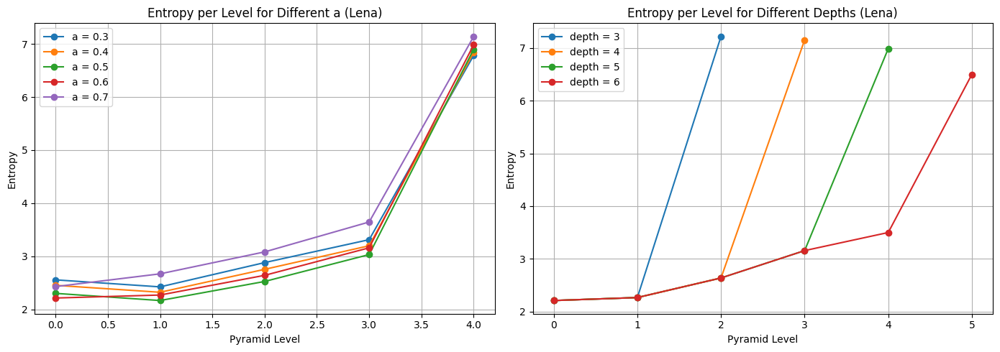

In [ ]:
# Visualize results
plot_entropy_analysis(lena, a_values, depth_values, fixed_depth=5, fixed_a=0.6, label="Lena")

In [ ]:
# Implementation on camera image
print_entropy_summary(camera, a_values, depth_values, fixed_depth=5, fixed_a=0.6, label="Camera")


Entropy per Level for Different a values (fixed depth = 5) — Camera
a = 0.30: L[0] = 2.2212 | L[1] = 2.1358 | L[2] = 2.3577 | L[3] = 2.7790 | L[4] = 6.9079
a = 0.40: L[0] = 2.1247 | L[1] = 2.0784 | L[2] = 2.3056 | L[3] = 2.6730 | L[4] = 6.9200
a = 0.50: L[0] = 1.9784 | L[1] = 1.9538 | L[2] = 2.1592 | L[3] = 2.4496 | L[4] = 6.8653
a = 0.60: L[0] = 1.9321 | L[1] = 2.0442 | L[2] = 2.3283 | L[3] = 2.6414 | L[4] = 6.8913
a = 0.70: L[0] = 2.1231 | L[1] = 2.3735 | L[2] = 2.6770 | L[3] = 3.0502 | L[4] = 7.0028

Entropy per Level for Different depth values (fixed a = 0.6) — Camera
depth = 3: L[0] = 1.9321 | L[1] = 2.0442 | L[2] = 7.0570
depth = 4: L[0] = 1.9321 | L[1] = 2.0442 | L[2] = 2.3283 | L[3] = 6.9884
depth = 5: L[0] = 1.9321 | L[1] = 2.0442 | L[2] = 2.3283 | L[3] = 2.6414 | L[4] = 6.8913
depth = 6: L[0] = 1.9321 | L[1] = 2.0442 | L[2] = 2.3283 | L[3] = 2.6414 | L[4] = 3.1307 | L[5] = 6.5431


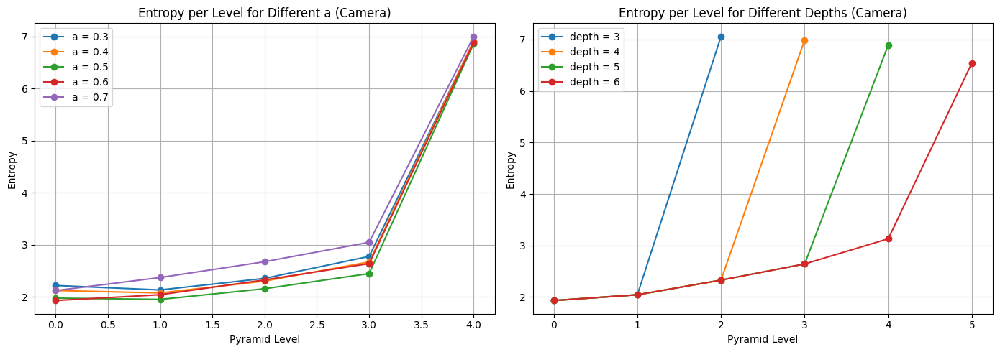

In [ ]:
# Visualize results
plot_entropy_analysis(camera, a_values, depth_values, fixed_depth=5, fixed_a=0.6, label="Camera")

#### Conclusions

Η μεταβολή της **παραμέτρου a** επηρεάζει την κατανομή πληροφορίας στην πυραμίδα:
μικρές τιμές κρατούν περισσότερη πληροφορία στα χαμηλά επίπεδα, ενώ μεγαλύτερες τιμές τη μεταφέρουν στα ανώτερα.

Η αύξηση του **βάθους (depth)** οδηγεί σε αύξηση της συνολικής εντροπίας, καθώς προστίθενται επίπεδα με σημαντικό περιεχόμενο χαμηλής συχνότητας.

Η εικόνα Lena, λόγω υφής και χρωματικής πολυπλοκότητας, παρουσιάζει υψηλότερες εντροπίες από την Camera, που έχει περισσότερο ομαλό φόντο.

Τα αποτελέσματα δείχνουν ότι η πληροφορία δεν κατανέμεται ισομερώς στα επίπεδα. Η εντροπία μπορεί να χρησιμοποιηθεί ως οδηγός για καλύτερη επιλογή παραμέτρων και προσαρμοστική κβαντοποίηση, ώστε να διατηρείται η κρίσιμη πληροφορία με αποδοτικό τρόπο.

### **5. Determining the optimal 'a' for entropy minimization in the Laplacian pyramid**

#### Helper Functions

Η συνάρτηση **find_optimal_a_per_level(image, a_values, depth, label)** εντοπίζει την τιμή του παραμέτρου a που ελαχιστοποιεί την εντροπία σε κάθε επίπεδο της Laplacian Πυραμίδας.

In [ ]:
# Finds and displays the optimal 'a' per level based on entropy, with detailed breakdown
def find_optimal_a_per_level(image, a_values, depth, label="Image"):
    # Dictionary to hold entropy per level for each 'a'
    entropy_map = {}

    print(f"\nComputing entropy for each 'a' and pyramid level ({label})...")
    for a in a_values:
        # Build Laplacian pyramid
        pyramid = L_Pyramid(image, a=a, depth=depth) if image.ndim == 2 else [L_Pyramid(image[:, :, c], a=a, depth=depth) for c in range(3)]

        # Compute entropy for each level
        entropies = compute_pyramid_entropy(pyramid)
        entropy_map[a] = entropies

        # Print per-level entropy for current 'a'
        print(f"\nEntropy per level for a = {a:.2f}:")
        for i, entropy in enumerate(entropies):
            print(f"  Level {i}: {entropy:.5f}")

    # Summary header
    print(f"\n{'=' * 40}")
    print(f"Summary: Optimal 'a' per level based on entropy ({label})")
    print(f"{'Level':>5} | " + " | ".join([f"a={a:.2f}" for a in a_values]) + " |  Best a  |  Min Entropy")
    print("-" * (8 + 12 * len(a_values) + 25))

    # Determine best 'a' for each level
    for level in range(depth):
        entropy_row = [entropy_map[a][level] for a in a_values]
        best_index = int(np.argmin(entropy_row))
        best_a = a_values[best_index]
        best_entropy = entropy_row[best_index]

        row = f"{level:>5} | " + " | ".join([f"{e:.5f}" for e in entropy_row])
        row += f" |   {best_a:.2f}   |   {best_entropy:.5f}"
        print(row)

#### Implementation

In [ ]:
# Implementation on lena image
find_optimal_a_per_level(lena, a_values, depth=depth, label="Lena")


Computing entropy for each 'a' and pyramid level (Lena)...

Entropy per level for a = 0.30:
  Level 0: 2.55496
  Level 1: 2.42263
  Level 2: 2.88015
  Level 3: 3.31211
  Level 4: 6.78578

Entropy per level for a = 0.40:
  Level 0: 2.45198
  Level 1: 2.32102
  Level 2: 2.75326
  Level 3: 3.19754
  Level 4: 6.84203

Entropy per level for a = 0.50:
  Level 0: 2.30038
  Level 1: 2.16548
  Level 2: 2.52453
  Level 3: 3.03133
  Level 4: 6.90082

Entropy per level for a = 0.60:
  Level 0: 2.21281
  Level 1: 2.26909
  Level 2: 2.64003
  Level 3: 3.15839
  Level 4: 6.98443

Entropy per level for a = 0.70:
  Level 0: 2.42801
  Level 1: 2.66839
  Level 2: 3.08173
  Level 3: 3.64523
  Level 4: 7.14183

Summary: Optimal 'a' per level based on entropy (Lena)
Level | a=0.30 | a=0.40 | a=0.50 | a=0.60 | a=0.70 |  Best a  |  Min Entropy
---------------------------------------------------------------------------------------------
    0 | 2.55496 | 2.45198 | 2.30038 | 2.21281 | 2.42801 |   0.60   |   2.

In [ ]:
# Implementation on camera image
find_optimal_a_per_level(camera, a_values, depth=depth, label="Camera")


Computing entropy for each 'a' and pyramid level (Camera)...

Entropy per level for a = 0.30:
  Level 0: 2.22124
  Level 1: 2.13582
  Level 2: 2.35770
  Level 3: 2.77896
  Level 4: 6.90787

Entropy per level for a = 0.40:
  Level 0: 2.12467
  Level 1: 2.07836
  Level 2: 2.30555
  Level 3: 2.67302
  Level 4: 6.92003

Entropy per level for a = 0.50:
  Level 0: 1.97843
  Level 1: 1.95383
  Level 2: 2.15921
  Level 3: 2.44956
  Level 4: 6.86526

Entropy per level for a = 0.60:
  Level 0: 1.93208
  Level 1: 2.04416
  Level 2: 2.32830
  Level 3: 2.64144
  Level 4: 6.89133

Entropy per level for a = 0.70:
  Level 0: 2.12307
  Level 1: 2.37354
  Level 2: 2.67701
  Level 3: 3.05022
  Level 4: 7.00275

Summary: Optimal 'a' per level based on entropy (Camera)
Level | a=0.30 | a=0.40 | a=0.50 | a=0.60 | a=0.70 |  Best a  |  Min Entropy
---------------------------------------------------------------------------------------------
    0 | 2.22124 | 2.12467 | 1.97843 | 1.93208 | 2.12307 |   0.60   | 

#### Conclusions

Με βάση την εντροπία κάθε επιπέδου, υπολογίστηκε η βέλτιστη τιμή `a` (από το εύρος [0.3, 0.7]) που ελαχιστοποιεί την πληροφορία (entropy) σε κάθε επίπεδο της πυραμίδας.

Lena:
- Οι βέλτιστες τιμές `a` συγκλίνουν γύρω από 0.5–0.6 για τα πρώτα επίπεδα
- Στο τελευταίο επίπεδο (L[4]), το `a = 0.3` είναι βέλτιστο (χαμηλότερη entropία)

Camera:
- Όλα τα επίπεδα έχουν ως βέλτιστο το `a = 0.5`
- Δηλώνει σταθερή συμπεριφορά και ομαλότητα στη διαχείριση πληροφορίας

**Συμπέρασμα:**

Η ανάλυση εντροπίας δείχνει ότι για τις περισσότερες περιπτώσεις, `a = 0.5` προσφέρει τη βέλτιστη κατανομή πληροφορίας κατά μήκος των επιπέδων.  



### **6. Image quantization using the best 'a' with different bin sizes**

#### Helper Functions

Η συνάρτηση **run_quantization_experiment(image, a, depth, bin_sizes, label)** εκτελεί πείραμα κβαντοποίησης και ανακατασκευής εικόνας μέσω Laplacian Πυραμίδας, για δοσμένο a, βάθος και μέγεθος bins.

In [ ]:
# Performs quantization and reconstruction for a given image, a value, and bin sizes
def run_quantization_experiment(image, a, depth, bin_sizes, label="Image"):
    print(f"\nRunning quantization for {label}")
    print(f"Using a = {a}, depth = {depth}, bin sizes = {bin_sizes}")

    # Build Laplacian pyramid
    if image.ndim == 2:
        lap_pyr = L_Pyramid(image, a=a, depth=depth)
        quantized_pyr = L_Quantization(lap_pyr, bin_sizes)
        reconstructed = L_Pyramid_Decode(quantized_pyr, a=a)
    else:
        # Color image — process each channel separately
        lap_pyr = [L_Pyramid(image[:, :, c], a=a, depth=depth) for c in range(3)]
        quantized_pyr = [L_Quantization(lap_pyr[c], bin_sizes) for c in range(3)]
        reconstructed_channels = [L_Pyramid_Decode(quantized_pyr[c], a=a) for c in range(3)]
        reconstructed = np.stack(reconstructed_channels, axis=2)

    # Prepare for display and comparison
    reconstructed_uint8 = np.clip(reconstructed, 0, 255).astype(np.uint8)
    original_uint8 = np.clip(image, 0, 255).astype(np.uint8)

    # Compare original and quantized-reconstructed image
    compare_to_original(original_uint8, reconstructed_uint8)

#### Implementation

In [ ]:
# Define bin sizes for two experiments
bin_sizes_1 = [30, 20, 15, 10, 5]
bin_sizes_2 = [5, 10, 15, 20, 30]

# Define optimal a (based on previous entropy analysis)
optimal_a_camera = 0.5  # from earlier results
optimal_a_lena = 0.5    # from earlier results

# Set depth
depth = 5

In [ ]:
# Run for Lena image
run_quantization_experiment(lena, a=optimal_a_lena, depth=depth, bin_sizes=bin_sizes_1, label="Lena (Exp 1)")
run_quantization_experiment(lena, a=optimal_a_lena, depth=depth, bin_sizes=bin_sizes_2, label="Lena (Exp 2)")


Running quantization for Lena (Exp 1)
Using a = 0.5, depth = 5, bin sizes = [30, 20, 15, 10, 5]


In [ ]:
# Run for Camera image
run_quantization_experiment(camera, a=optimal_a_camera, depth=depth, bin_sizes=bin_sizes_1, label="Camera (Exp 1)")
run_quantization_experiment(camera, a=optimal_a_camera, depth=depth, bin_sizes=bin_sizes_2, label="Camera (Exp 2)")

#### Conclusions

Στο πρώτο πείραμα ([30, 20, 15, 10, 5]), όπου τα μεγαλύτερα bin sizes εφαρμόζονται στα χαμηλά επίπεδα της πυραμίδας (δηλαδή στις υψηλές συχνότητες), η ποιότητα της ανακατασκευής παραμένει σε ικανοποιητικό επίπεδο.
Η παραμόρφωση είναι περιορισμένη και η οπτική εντύπωση διατηρείται φυσική, η αντίθεση και τα περιγράμματα διατηρούνται καλά.


Αντίθετα, στο δεύτερο πείραμα ([5, 10, 15, 20, 30]), όπου η χονδροειδής κβαντοποίηση εφαρμόζεται στα υψηλότερα επίπεδα της πυραμίδας (δηλαδή στις χαμηλές συχνότητες), προκύπτει εντονότερη παραμόρφωση.


Συμπέρασμα:
Τα αποτελέσματα επιβεβαιώνουν πως η επιλογή των bin sizes με βάση την ανθρώπινη οπτική ευαισθησία —δηλαδή λεπτότερη κβαντοποίηση στις χαμηλές συχνότητες (υψηλά επίπεδα) και αυστηρότερη στα πρώτα επίπεδα της πυραμίδας— οδηγεί σε καλύτερη οπτική ποιότητα και πιο αποδοτική συμπίεση.

## **Conclusion**

Τα πειραματικά αποτελέσματα έδειξαν ότι:

- Η **παράμετρος a**, που ορίζει το βάρος του Gaussian φίλτρου, επηρεάζει την ισορροπία μεταξύ ομαλότητας και διατήρησης λεπτομερειών. Τιμές στο εύρος 0.4–0.6 προσφέρουν τη βέλτιστη συμπεριφορά σε επίπεδο εντροπίας και ποιότητας ανακατασκευής.

- Η **αύξηση του βάθους** της πυραμίδας επιτρέπει μεγαλύτερη συμπίεση, αλλά οδηγεί σε συσσώρευση πληροφορίας στα ανώτερα επίπεδα, όπου και εντοπίζεται αυξημένη εντροπία και ευαισθησία στην κβαντοποίηση.

- Η **ανάλυση εντροπίας** ανά επίπεδο αποκάλυψε ότι κάθε επίπεδο φέρει διαφορετική πληροφοριακή βαρύτητα, κάτι που υποδεικνύει την αναγκαιότητα για μη ομοιόμορφη, προσαρμοστική κβαντοποίηση ανάλογα με τη συχνότητα.

- Στα **πειράματα κβαντοποίησης**, διαπιστώθηκε πως η σωστή στρατηγική κατανομής bin sizes (δηλ. μικρότερα bins στα χαμηλά επίπεδα, όπου βρίσκονται οι υψηλές συχνότητες, και μεγαλύτερα bins στα ανώτερα επίπεδα) οδηγεί σε υψηλής ποιότητας ανακατασκευή με ελεγχόμενο σφάλμα.
Αντίθετα, αντιστροφή αυτής της στρατηγικής προκαλεί ορατή παραμόρφωση και απώλεια κρίσιμης πληροφορίας.

Συμπέρασματικά, η Laplacian Πυραμίδα προσφέρει ένα ισχυρό και εύκαμπτο πλαίσιο για ανάλυση, συμπίεση και επεξεργασία εικόνων, αρκεί να αξιοποιηθεί με κατάλληλα επιλεγμένες παραμέτρους (a, βάθος, bin sizes).
Η προσέγγιση είναι πλήρως συμβατή με τα χαρακτηριστικά του ανθρώπινου οπτικού συστήματος, καθιστώντας την ιδανική για εφαρμογές όπου απαιτείται υψηλή οπτική ποιότητα με ελεγχόμενο κόστος υπολογισμού και αποθήκευσης.